# Task 3 — Jointly Trained Soft Mixture-of-Experts Restoration
**Colab notebook, Google Drive-backed.** Reads the trained classifier and 3 specialists from Task 2's Drive folder (`task2_artifacts_correct/`) and writes all Task 3 outputs to its own folder (`task3_artifacts/`), so nothing from Task 2 is touched or overwritten. **Run Task 2 first** — this notebook asserts Task 2's checkpoints exist and stops with a clear error if they don't.

**What this builds:** `w = softmax(G(x)/τ)` over 4 branches (identity/clean, salt-and-pepper, blur, occlusion), then `x_hat = w0*x + w1*A_salt(x) + w2*A_blur(x) + w3*A_occ(x)` — a fully differentiable weighted combination, so gate and experts can be trained jointly through the final reconstruction error. Both the gate and all 3 experts are initialized from Task 2's trained weights (never random), trained in two stages: a short **warm-up** with experts frozen (gate only), then **joint fine-tuning** with everything unfrozen at a smaller learning rate.

**Debugging tools, consistent with Task 2:** an overfit sanity check adapted for the joint system (can gate+experts, starting from the Task 2 initialization, memorize a small balanced batch?), and `check_routing_collapse()` — flags an expert with near-zero average weight (inactive) or near-1.0 average weight regardless of input (dominating everything, i.e. the gate ignoring the input). This runs automatically during warm-up, every 5 epochs of joint fine-tuning, and as part of the final gating analysis.

## 1. Install dependencies

In [ ]:
# Colab already has torch, torchvision, opencv, pandas, matplotlib,
# scikit-learn, tqdm. Only these are missing:
!pip install -q optuna pytorch-msssim onnx onnxruntime mlflow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 54.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/

## 2. Mount Drive, paths, checkpoint helpers
Points at Task 2's Drive folder to *read* the classifier/specialists, and at a new Task-3-only folder to *write* everything this notebook produces.

In [ ]:
import os, glob, json, random, time, math
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from PIL import Image
import matplotlib.pyplot as plt
from pytorch_msssim import ssim as ssim_metric
from sklearn.metrics import accuracy_score

# ============================================================
# Same Drive base as Task 2, so this notebook can find and load the
# trained classifier + 3 specialists from there. Task-3-specific outputs
# (gate/joint checkpoints, results, ONNX) go in their own subfolders so
# nothing from Task 2 gets overwritten.
# ============================================================

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_BASE = '/content/drive/MyDrive/task2_artifacts_correct'   # Task 2's folder -- read classifier/specialists from here
TASK3_BASE = '/content/drive/MyDrive/task3_artifacts'           # Task 3's own folder

DATA_ROOT = os.path.join(DRIVE_BASE, 'oxford_pet_raw')
MANIFEST_DIR = os.path.join(DRIVE_BASE, 'manifests')
CKPT_DIR = os.path.join(DRIVE_BASE, 'checkpoints')          # Task 2 checkpoints (read-only from here)
RESULTS_DIR = os.path.join(DRIVE_BASE, 'results')            # Task 2 results (read-only from here)

MOE_CKPT_DIR = os.path.join(TASK3_BASE, 'checkpoints')
MOE_RESULTS_DIR = os.path.join(TASK3_BASE, 'results')
MOE_ONNX_DIR = os.path.join(TASK3_BASE, 'onnx_export')
MOE_SNAPSHOT_DIR = os.path.join(MOE_RESULTS_DIR, 'snapshots')

for d in [DATA_ROOT, MANIFEST_DIR, CKPT_DIR, RESULTS_DIR,
          MOE_CKPT_DIR, MOE_RESULTS_DIR, MOE_ONNX_DIR, MOE_SNAPSHOT_DIR]:
    os.makedirs(d, exist_ok=True)

assert os.path.isdir('/content/drive/MyDrive'), 'Google Drive is not mounted.'
print('Task 2 base (read):', DRIVE_BASE)
print('Task 3 base (write):', TASK3_BASE)

SEED = 42
IMG_SIZE = 128


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)


def find_file(filename, subdir='checkpoints', base=None):
    """base=None searches Task 2's DRIVE_BASE (for the classifier/specialists);
    pass base=TASK3_BASE (or use find_moe_file below) for Task 3's own files."""
    base = base or DRIVE_BASE
    path = os.path.join(base, subdir, filename)
    return path if os.path.exists(path) else None


def find_moe_file(filename, subdir='checkpoints'):
    return find_file(filename, subdir=subdir, base=TASK3_BASE)


def save_checkpoint(state, filename, subdir='checkpoints', base=None):
    base = base or TASK3_BASE  # Task 3 cells save into TASK3_BASE by default
    d = os.path.join(base, subdir)
    os.makedirs(d, exist_ok=True)
    path = os.path.join(d, filename)
    tmp_path = path + '.tmp'
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)
    return path


def verify_checkpoint(filename, subdir='checkpoints', base=None, required_keys=('model_state',)):
    base = base or TASK3_BASE
    path = find_file(filename, subdir, base=base)
    if path is None:
        print(f'verify_checkpoint: {filename} not found.')
        return False
    try:
        ckpt = torch.load(path, map_location='cpu')
    except Exception as e:
        print(f'verify_checkpoint: {filename} FAILED TO LOAD ({e})')
        return False
    missing = [k for k in required_keys if k not in ckpt]
    if missing:
        print(f'verify_checkpoint: {filename} is missing keys {missing}.')
        return False
    print(f'verify_checkpoint: {filename} OK ({path}, {os.path.getsize(path)/1e6:.1f} MB)')
    return True


def load_json_if_exists(filename, subdir='', base=None):
    base = base or DRIVE_BASE
    path = os.path.join(base, subdir, filename) if subdir else os.path.join(base, filename)
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f), path
    return None, None


Mounted at /content/drive
Task 2 base (read): /content/drive/MyDrive/task2_artifacts_correct
Task 3 base (write): /content/drive/MyDrive/task3_artifacts
Using device: cuda


## 3. Dataset (reused from Task 2 — same split, same manifests)

In [ ]:
# Reuses the exact same split as Task 1 if data_split.json is found on
# Drive. Otherwise regenerates it -- with the same seed=42 and the same
# torchvision dataset ordering, this reproduces the identical split.

trainval_raw = datasets.OxfordIIITPet(root=DATA_ROOT, split='trainval', target_types='category', download=True)
test_raw = datasets.OxfordIIITPet(root=DATA_ROOT, split='test', target_types='category', download=True)
print('Official trainval (development) size:', len(trainval_raw))
print('Official test size (untouched until final eval):', len(test_raw))

trainval_paths = [str(p) for p in trainval_raw._images]
test_paths_all = [str(p) for p in test_raw._images]


def paths_look_valid(manifest_or_paths):
    """A data_split.json (or manifest) saved from a different environment
    (e.g. an old Kaggle run) would have paths starting with /kaggle/... --
    catch that instead of silently trying to load images that don't exist
    here."""
    if not manifest_or_paths:
        return False
    sample = manifest_or_paths[0]
    sample_path = sample['path'] if isinstance(sample, dict) else sample
    return os.path.exists(sample_path)


split_record, split_source = load_json_if_exists('data_split.json')
if split_record is not None and paths_look_valid(split_record['train']):
    train_paths, val_paths, test_paths = split_record['train'], split_record['val'], split_record['test']
    print(f'Reusing existing split from {split_source}')
else:
    if split_record is not None:
        print('Existing data_split.json has paths that don\'t exist here (from a different '
              'environment?) -- regenerating.')
    rng = np.random.default_rng(SEED)
    indices = np.arange(len(trainval_paths))
    rng.shuffle(indices)
    split_point = int(0.8 * len(indices))
    train_idx, val_idx = indices[:split_point], indices[split_point:]
    train_paths = [trainval_paths[i] for i in train_idx]
    val_paths = [trainval_paths[i] for i in val_idx]
    test_paths = test_paths_all
    with open(os.path.join(DRIVE_BASE, 'data_split.json'), 'w') as f:
        json.dump({'train': train_paths, 'val': val_paths, 'test': test_paths}, f)
    print('Generated a new split (seed=42, matches Task 1)')

print(f'Train: {len(train_paths)}  Val: {len(val_paths)}  Test: {len(test_paths)}')


Official trainval (development) size: 3680
Official test size (untouched until final eval): 3669
Reusing existing split from /content/drive/MyDrive/task2_artifacts_correct/data_split.json
Train: 2944  Val: 736  Test: 3669


## 3b. Preload all images into RAM

In [ ]:
# ============================================================
# Preload every image into RAM, once, using threads for parallel I/O.
#
# WHY: Google Drive is mounted as a FUSE filesystem. Reading thousands of
# small JPEGs from it -- especially from multiple DataLoader worker
# processes at once -- is extremely slow and can stall for minutes per
# batch (this is the #1 cause of an Optuna trial or training epoch
# appearing "stuck" on Colab). The Oxford-IIIT Pet dataset resized to
# 128x128 uint8 fits comfortably in RAM (~360MB total), so we pay the
# Drive I/O cost exactly once, here, with threads (I/O-bound reads
# parallelize well even under the GIL) instead of paying it every batch
# of every epoch of every Optuna trial.
# ============================================================

from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm


def load_and_resize(path, size=IMG_SIZE):
    img = Image.open(path).convert('RGB').resize((size, size), Image.BILINEAR)
    return np.array(img, dtype=np.uint8)  # HWC uint8


def preload_to_ram(paths, desc, max_workers=16):
    cache = {}
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        results = list(tqdm(ex.map(load_and_resize, paths), total=len(paths), desc=desc))
    for p, img in zip(paths, results):
        cache[p] = img
    return cache


IMAGE_CACHE = {}
IMAGE_CACHE.update(preload_to_ram(train_paths, 'Preloading train'))
IMAGE_CACHE.update(preload_to_ram(val_paths, 'Preloading val'))
IMAGE_CACHE.update(preload_to_ram(test_paths, 'Preloading test'))
print(f'Preloaded {len(IMAGE_CACHE)} images into RAM '
      f'(~{len(IMAGE_CACHE) * IMG_SIZE * IMG_SIZE * 3 / 1e6:.0f} MB). '
      f'All subsequent epochs read from memory, not Drive.')


Preloading train:   0%|          | 0/2944 [00:00<?, ?it/s]

Preloading val:   0%|          | 0/736 [00:00<?, ?it/s]

Preloading test:   0%|          | 0/3669 [00:00<?, ?it/s]

Preloaded 7349 images into RAM (~361 MB). All subsequent epochs read from memory, not Drive.


## 4. Corruption functions

In [ ]:
# ============================================================
# Corruption primitives. All operate on an HWC uint8 RGB numpy
# array and are driven by an explicit numpy Generator so that
# both dynamic (training) and deterministic (val/test) usage
# share exactly the same implementation.
# ============================================================

CORRUPTION_TYPES = ['clean', 'salt_pepper', 'gaussian_blur', 'occlusion']

# --- Training-time sampling ranges (also used as bounds for val manifest) ---
SP_PROB_RANGE = (0.02, 0.15)
BLUR_KERNELS = [3, 5, 7]
BLUR_SIGMA_RANGE = (0.5, 2.5)
OCC_NUM_RECTS_RANGE = (1, 3)          # inclusive
OCC_AREA_FRAC_RANGE = (0.10, 0.35)

# --- Fixed test-time severities (three levels per corruption) ---
TEST_SP_PROBS = [0.03, 0.08, 0.15]
TEST_BLUR_CFGS = [(3, 0.7), (5, 1.5), (7, 2.5)]
TEST_OCC_CFGS = [(1, 0.10), (2, 0.20), (3, 0.35)]  # (num_rects, area_frac)


def apply_salt_pepper(img, prob, rng):
    """img: HWC uint8. Replace selected pixels with black/white, 50/50."""
    out = img.copy()
    h, w = out.shape[:2]
    corrupt_mask = rng.random((h, w)) < prob
    salt_mask = rng.random((h, w)) < 0.5
    out[corrupt_mask & salt_mask] = 255
    out[corrupt_mask & ~salt_mask] = 0
    return out


def apply_gaussian_blur(img, kernel_size, sigma):
    return cv2.GaussianBlur(img, (kernel_size, kernel_size), sigmaX=sigma, sigmaY=sigma)


def sample_rectangles(h, w, num_rects, target_area_frac, rng):
    """Randomly place `num_rects` rectangles whose combined area is
    approximately `target_area_frac` of the image."""
    total_area = h * w
    target_area = target_area_frac * total_area
    splits = rng.dirichlet(np.ones(num_rects)) * target_area
    rects = []
    for area in splits:
        aspect = rng.uniform(0.5, 2.0)
        rw = int(round(math.sqrt(area * aspect)))
        rw = max(1, min(rw, w))
        rh = int(round(area / rw))
        rh = max(1, min(rh, h))
        x0 = int(rng.integers(0, max(1, w - rw + 1)))
        y0 = int(rng.integers(0, max(1, h - rh + 1)))
        rects.append([x0, y0, rw, rh])
    return rects


def apply_occlusion(img, rects):
    out = img.copy()
    for (x0, y0, rw, rh) in rects:
        out[y0:y0 + rh, x0:x0 + rw] = 0
    return out


def sample_dynamic_corruption(img_np, rng):
    """Used during TRAINING: sample a fresh corruption type + severity
    every time an image is loaded. Returns (corrupted_img, label, params)."""
    ctype = rng.choice(CORRUPTION_TYPES)  # equal probability, p=None -> uniform
    h, w = img_np.shape[:2]

    if ctype == 'clean':
        return img_np.copy(), ctype, {}

    if ctype == 'salt_pepper':
        prob = float(rng.uniform(*SP_PROB_RANGE))
        out = apply_salt_pepper(img_np, prob, rng)
        return out, ctype, {'prob': prob}

    if ctype == 'gaussian_blur':
        kernel = int(rng.choice(BLUR_KERNELS))
        sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
        out = apply_gaussian_blur(img_np, kernel, sigma)
        return out, ctype, {'kernel': kernel, 'sigma': sigma}

    if ctype == 'occlusion':
        n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
        area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
        rects = sample_rectangles(h, w, n_rects, area_frac, rng)
        out = apply_occlusion(img_np, rects)
        return out, ctype, {'rects': rects, 'area_frac': area_frac}

    raise ValueError(ctype)


def apply_corruption_from_params(img_np, ctype, params):
    """Re-apply a previously-recorded corruption (used for val/test manifests)."""
    if ctype == 'clean':
        return img_np.copy()
    if ctype == 'salt_pepper':
        rng = np.random.default_rng(params['seed'])
        return apply_salt_pepper(img_np, params['prob'], rng)
    if ctype == 'gaussian_blur':
        return apply_gaussian_blur(img_np, params['kernel'], params['sigma'])
    if ctype == 'occlusion':
        return apply_occlusion(img_np, params['rects'])
    raise ValueError(ctype)


## 5. Deterministic manifests

In [ ]:
# ============================================================
# Deterministic corruption manifests for validation and test.
# Generated once, saved to Drive as JSON, and re-loaded on every
# future run so results are perfectly reproducible.
# ============================================================

VAL_MANIFEST_PATH = os.path.join(MANIFEST_DIR, 'val_manifest.json')
TEST_MANIFEST_PATH = os.path.join(MANIFEST_DIR, 'test_manifest.json')

VAL_MANIFEST_SEED = 1000
TEST_MANIFEST_SEED = 2000
CTYPE_OFFSET = {'clean': 0, 'salt_pepper': 1, 'gaussian_blur': 2, 'occlusion': 3}


def build_val_manifest(paths):
    manifest = []
    for idx, path in enumerate(paths):
        seed = VAL_MANIFEST_SEED + idx
        rng = np.random.default_rng(seed)
        ctype = rng.choice(CORRUPTION_TYPES)

        if ctype == 'clean':
            params = {}
        elif ctype == 'salt_pepper':
            prob = float(rng.uniform(*SP_PROB_RANGE))
            mask_seed = int(rng.integers(0, 2**31 - 1))
            params = {'prob': prob, 'seed': mask_seed}
        elif ctype == 'gaussian_blur':
            kernel = int(rng.choice(BLUR_KERNELS))
            sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
            params = {'kernel': kernel, 'sigma': sigma}
        else:  # occlusion
            n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
            area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
            rects = sample_rectangles(IMG_SIZE, IMG_SIZE, n_rects, area_frac, rng)
            params = {'rects': rects, 'area_frac': area_frac}

        manifest.append({'path': path, 'ctype': ctype, 'severity': 'na', 'params': params, 'seed': seed})
    return manifest


def build_test_manifest(paths):
    """Every test image gets: 1 clean copy + 3 severities x 3 corruption
    types = 10 deterministic variants, matching the fixed severities
    required for final evaluation."""
    manifest = []
    for idx, path in enumerate(paths):
        manifest.append({'path': path, 'ctype': 'clean', 'severity': 'na', 'params': {}})

        for sev_idx, (sev_name, prob) in enumerate(zip(['low', 'medium', 'high'], TEST_SP_PROBS)):
            seed = TEST_MANIFEST_SEED * 1_000_003 + idx * 97 + CTYPE_OFFSET['salt_pepper'] * 17 + sev_idx
            manifest.append({'path': path, 'ctype': 'salt_pepper', 'severity': sev_name,
                              'params': {'prob': prob, 'seed': seed}})

        for sev_idx, (sev_name, (kernel, sigma)) in enumerate(zip(['low', 'medium', 'high'], TEST_BLUR_CFGS)):
            manifest.append({'path': path, 'ctype': 'gaussian_blur', 'severity': sev_name,
                              'params': {'kernel': kernel, 'sigma': sigma}})

        for sev_idx, (sev_name, (n_rects, area_frac)) in enumerate(zip(['low', 'medium', 'high'], TEST_OCC_CFGS)):
            seed = TEST_MANIFEST_SEED * 1_000_003 + idx * 97 + CTYPE_OFFSET['occlusion'] * 17 + sev_idx
            rng = np.random.default_rng(seed)
            rects = sample_rectangles(IMG_SIZE, IMG_SIZE, n_rects, area_frac, rng)
            manifest.append({'path': path, 'ctype': 'occlusion', 'severity': sev_name,
                              'params': {'rects': rects, 'area_frac': area_frac}})
    return manifest


if os.path.exists(VAL_MANIFEST_PATH):
    with open(VAL_MANIFEST_PATH) as f:
        val_manifest = json.load(f)
    print('Loaded existing val manifest:', len(val_manifest), 'entries')
else:
    val_manifest = build_val_manifest(val_paths)
    with open(VAL_MANIFEST_PATH, 'w') as f:
        json.dump(val_manifest, f)
    print('Generated new val manifest:', len(val_manifest), 'entries')

def build_specialist_val_manifest(paths, ctype, seed_offset):
    """A DEDICATED validation manifest for one specialist: every val image
    gets exactly one deterministic corruption of THIS type (not a quarter
    of them, as in the shared val_manifest above). This matters a lot --
    ~5% of the dataset (val_manifest filtered to one type) is a small,
    noisy validation signal, and a noisy signal makes early stopping fire
    too early, before the model has actually converged. Using the FULL val
    split per specialist (4x more data) gives a much more reliable stopping
    decision."""
    manifest = []
    for idx, path in enumerate(paths):
        seed = VAL_MANIFEST_SEED + seed_offset + idx
        rng = np.random.default_rng(seed)
        if ctype == 'salt_pepper':
            prob = float(rng.uniform(*SP_PROB_RANGE))
            mask_seed = int(rng.integers(0, 2**31 - 1))
            params = {'prob': prob, 'seed': mask_seed}
        elif ctype == 'gaussian_blur':
            kernel = int(rng.choice(BLUR_KERNELS))
            sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
            params = {'kernel': kernel, 'sigma': sigma}
        else:  # occlusion
            n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
            area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
            rects = sample_rectangles(IMG_SIZE, IMG_SIZE, n_rects, area_frac, rng)
            params = {'rects': rects, 'area_frac': area_frac}
        manifest.append({'path': path, 'ctype': ctype, 'severity': 'na', 'params': params, 'seed': seed})
    return manifest


# distinct large seed offsets so the three specialists' manifests don't
# collide with each other or with the shared val_manifest's seeds
SPECIALIST_VAL_SEED_OFFSETS = {'salt_pepper': 500_000, 'gaussian_blur': 600_000, 'occlusion': 700_000}
specialist_val_manifest = {}
for _ctype, _offset in SPECIALIST_VAL_SEED_OFFSETS.items():
    _path = os.path.join(MANIFEST_DIR, f'val_manifest_{_ctype}.json')
    if os.path.exists(_path):
        with open(_path) as f:
            specialist_val_manifest[_ctype] = json.load(f)
    else:
        specialist_val_manifest[_ctype] = build_specialist_val_manifest(val_paths, _ctype, _offset)
        with open(_path, 'w') as f:
            json.dump(specialist_val_manifest[_ctype], f)
    print(f'Specialist val manifest [{_ctype}]: {len(specialist_val_manifest[_ctype])} entries '
          f'(vs. ~{len(val_manifest)//4} in the old shared-manifest-filtered approach)')

if os.path.exists(TEST_MANIFEST_PATH):
    with open(TEST_MANIFEST_PATH) as f:
        test_manifest = json.load(f)
    print('Loaded existing test manifest:', len(test_manifest), 'entries')
else:
    test_manifest = build_test_manifest(test_paths)
    with open(TEST_MANIFEST_PATH, 'w') as f:
        json.dump(test_manifest, f)
    print('Generated new test manifest:', len(test_manifest), 'entries (~10x test set size)')


Loaded existing val manifest: 736 entries
Specialist val manifest [salt_pepper]: 736 entries (vs. ~184 in the old shared-manifest-filtered approach)
Specialist val manifest [gaussian_blur]: 736 entries (vs. ~184 in the old shared-manifest-filtered approach)
Specialist val manifest [occlusion]: 736 entries (vs. ~184 in the old shared-manifest-filtered approach)
Loaded existing test manifest: 36690 entries


## 6. Dataset classes

In [ ]:
# ============================================================
# Dataset classes. All read the clean image from IMAGE_CACHE (RAM).
#
#   - PetManifestDataset: deterministic corruption from a manifest
#     (used for validation / test, for both the classifier and specialists,
#     and as the "oracle label" source for routing evaluation).
#   - ClassifierTrainDataset: EXACTLY class-balanced training data for the
#     4-class classifier (see the note on the period-4 index trick below).
#   - SpecialistTrainDataset: dynamic single-corruption-type training data
#     for one specialist autoencoder.
# ============================================================

def to_tensor(img_np):
    return torch.from_numpy(img_np.astype(np.float32) / 255.0).permute(2, 0, 1).contiguous()


def get_clean_image(path):
    cached = IMAGE_CACHE.get(path)
    if cached is not None:
        return cached
    return load_and_resize(path)


class PetManifestDataset(Dataset):
    def __init__(self, manifest, img_size=IMG_SIZE):
        self.manifest = manifest
        self.img_size = img_size

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        entry = self.manifest[idx]
        clean_np = get_clean_image(entry['path'])
        corrupted_np = apply_corruption_from_params(clean_np, entry['ctype'], entry['params'])
        return {
            'clean': to_tensor(clean_np),
            'corrupted': to_tensor(corrupted_np),
            'ctype': entry['ctype'],
            'severity': entry.get('severity', 'na'),
            'label': CORRUPTION_TYPES.index(entry['ctype']),
        }


class ClassifierTrainDataset(Dataset):
    """Exactly class-balanced training data: the class is fixed by
    `idx % 4` (a period-4 sequence), so ANY contiguous window of indices
    whose length is a multiple of 4 contains exactly length/4 samples of
    each class -- true for every batch, regardless of where it starts.
    Used with shuffle=False and batch_size a multiple of 4; the actual
    IMAGE (and, for corrupted classes, the severity) is still freshly
    randomized every call, so there's no loss of training variety."""

    def __init__(self, paths, length, img_size=IMG_SIZE):
        self.paths = paths
        self.length = length
        self.img_size = img_size

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        ctype = CORRUPTION_TYPES[idx % 4]
        label = idx % 4
        rng = np.random.default_rng()
        path = self.paths[int(rng.integers(0, len(self.paths)))]
        clean_np = get_clean_image(path)

        if ctype == 'clean':
            corrupted_np = clean_np.copy()
        elif ctype == 'salt_pepper':
            prob = float(rng.uniform(*SP_PROB_RANGE))
            corrupted_np = apply_salt_pepper(clean_np, prob, rng)
        elif ctype == 'gaussian_blur':
            kernel = int(rng.choice(BLUR_KERNELS))
            sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
            corrupted_np = apply_gaussian_blur(clean_np, kernel, sigma)
        else:  # occlusion
            n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
            area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
            rects = sample_rectangles(self.img_size, self.img_size, n_rects, area_frac, rng)
            corrupted_np = apply_occlusion(clean_np, rects)

        return {'corrupted': to_tensor(corrupted_np), 'label': label, 'ctype': ctype}


class SpecialistTrainDataset(Dataset):
    """Dynamic training data for ONE specialist: every sample is the given
    corruption type only (never clean, never another type), fresh severity
    sampled every call."""

    def __init__(self, paths, ctype, img_size=IMG_SIZE):
        assert ctype in ('salt_pepper', 'gaussian_blur', 'occlusion')
        self.paths = paths
        self.ctype = ctype
        self.img_size = img_size

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        clean_np = get_clean_image(self.paths[idx])
        rng = np.random.default_rng()
        if self.ctype == 'salt_pepper':
            prob = float(rng.uniform(*SP_PROB_RANGE))
            corrupted_np = apply_salt_pepper(clean_np, prob, rng)
        elif self.ctype == 'gaussian_blur':
            kernel = int(rng.choice(BLUR_KERNELS))
            sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
            corrupted_np = apply_gaussian_blur(clean_np, kernel, sigma)
        else:
            n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
            area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
            rects = sample_rectangles(self.img_size, self.img_size, n_rects, area_frac, rng)
            corrupted_np = apply_occlusion(clean_np, rects)
        return {'clean': to_tensor(clean_np), 'corrupted': to_tensor(corrupted_np)}


def make_loader(dataset, batch_size, shuffle, num_workers=0, drop_last=None):
    if drop_last is None:
        drop_last = shuffle
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                       num_workers=num_workers, pin_memory=(DEVICE.type == 'cuda'),
                       drop_last=drop_last)


val_ds = PetManifestDataset(val_manifest)
test_ds = PetManifestDataset(test_manifest)
clf_train_ds = ClassifierTrainDataset(train_paths, length=len(train_paths))

specialist_train_ds = {
    'salt_pepper': SpecialistTrainDataset(train_paths, 'salt_pepper'),
    'gaussian_blur': SpecialistTrainDataset(train_paths, 'gaussian_blur'),
    'occlusion': SpecialistTrainDataset(train_paths, 'occlusion'),
}

print('val/test sizes:', len(val_ds), len(test_ds))
print('classifier train dataset size:', len(clf_train_ds))
_sample = clf_train_ds[0]
print('classifier sample:', _sample['ctype'], _sample['label'], _sample['corrupted'].shape)


val/test sizes: 736 36690
classifier train dataset size: 2944
classifier sample: clean 0 torch.Size([3, 128, 128])


## 7. Classifier architecture (needed to load Task 2's trained gate)

In [ ]:
# ============================================================
# Corruption classifier: C(x) -> [p_clean, p_salt, p_blur, p_occlusion]
# Small CNN (this is an easy 4-way problem -- the corruption types look
# nothing alike -- so a deep/heavy network isn't needed).
# ============================================================

class CorruptionClassifier(nn.Module):
    def __init__(self, n_layers=4, base_width=32, dropout=0.2, num_classes=4, img_size=None):
        # img_size accepted (and ignored) so the saved checkpoint config
        # dict -- which also carries img_size for record-keeping -- can be
        # passed straight back into the constructor via **config.
        super().__init__()
        layers = []
        cin = 3
        for i in range(n_layers):
            cout = base_width * (2 ** i)
            layers += [nn.Conv2d(cin, cout, 3, stride=2, padding=1),
                       nn.GroupNorm(8, cout), nn.ReLU(inplace=True)]
            cin = cout
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(cin, num_classes)

    def forward(self, x):
        h = self.features(x)
        h = self.pool(h).flatten(1)
        h = self.dropout(h)
        return self.fc(h)  # raw logits


_test_clf = CorruptionClassifier(n_layers=4, base_width=32, dropout=0.2)
_test_out = _test_clf(torch.rand(4, 3, IMG_SIZE, IMG_SIZE))
print('Classifier output shape:', _test_out.shape,
      '| params:', sum(p.numel() for p in _test_clf.parameters()))
del _test_clf, _test_out


Classifier output shape: torch.Size([4, 4]) | params: 390404


## 8. Specialist architecture (needed to load Task 2's trained experts)

In [ ]:
# ============================================================
# Specialist autoencoder architecture. Each specialist only ever sees ONE
# corruption type, so there's no need for the degradation-conditioning
# machinery from Task 1's universal model -- a plain spatial-bottleneck
# convolutional autoencoder is the right amount of complexity here.
# Same fixes as Task 1's corrected architecture: a genuine SPATIAL
# bottleneck (not flattened to a vector) and resize-convolution upsampling
# (not ConvTranspose2d), both of which avoid blurry reconstructions.
# ============================================================

class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, ch)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, ch)

    def forward(self, x):
        h = F.relu(self.norm1(self.conv1(x)))
        h = self.norm2(self.conv2(h))
        return F.relu(x + h)


class DownBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 4, stride=2, padding=1)
        self.norm = nn.GroupNorm(8, cout)

    def forward(self, x):
        return F.relu(self.norm(self.conv(x)))


class UpBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, padding=1)
        self.norm = nn.GroupNorm(8, cout)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return F.relu(self.norm(self.conv(x)))


class SpecialistEncoder(nn.Module):
    def __init__(self, base_channels=48, bottleneck_channels=128, dropout=0.1, n_res_blocks=2):
        super().__init__()
        c = base_channels
        self.stem = nn.Sequential(nn.Conv2d(3, c, 3, padding=1), nn.GroupNorm(8, c), nn.ReLU(inplace=True))
        self.down1 = DownBlock(c, c * 2)
        self.down2 = DownBlock(c * 2, c * 4)
        self.down3 = DownBlock(c * 4, c * 8)
        self.down4 = DownBlock(c * 8, c * 8)
        self.res = nn.Sequential(*[ResBlock(c * 8) for _ in range(n_res_blocks)])
        self.dropout = nn.Dropout2d(dropout)
        self.squeeze = nn.Conv2d(c * 8, bottleneck_channels, 1)

    def forward(self, x):
        h = self.stem(x)
        h = self.down1(h); h = self.down2(h); h = self.down3(h); h = self.down4(h)
        h = self.res(h)
        h = self.dropout(h)
        return self.squeeze(h)


class SpecialistDecoder(nn.Module):
    def __init__(self, base_channels=48, bottleneck_channels=128, dropout=0.1, n_res_blocks=2):
        super().__init__()
        c = base_channels
        self.expand = nn.Conv2d(bottleneck_channels, c * 8, 1)
        self.res = nn.Sequential(*[ResBlock(c * 8) for _ in range(n_res_blocks)])
        self.up1 = UpBlock(c * 8, c * 8)
        self.up2 = UpBlock(c * 8, c * 4)
        self.up3 = UpBlock(c * 4, c * 2)
        self.up4 = UpBlock(c * 2, c)
        self.dropout = nn.Dropout2d(dropout)
        self.out_conv = nn.Conv2d(c, 3, 3, padding=1)

    def forward(self, z):
        h = self.expand(z)
        h = self.res(h)
        h = self.up1(h); h = self.up2(h); h = self.up3(h); h = self.up4(h)
        h = self.dropout(h)
        return torch.sigmoid(self.out_conv(h))


class SpecialistAutoencoder(nn.Module):
    def __init__(self, base_channels=48, bottleneck_channels=128, dropout=0.1, n_res_blocks=2, img_size=IMG_SIZE):
        super().__init__()
        assert img_size % 16 == 0
        self.encoder = SpecialistEncoder(base_channels, bottleneck_channels, dropout, n_res_blocks)
        self.decoder = SpecialistDecoder(base_channels, bottleneck_channels, dropout, n_res_blocks)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def combined_loss(x_hat, x, alpha):
    l1 = F.l1_loss(x_hat, x)
    s = ssim_metric(x_hat, x, data_range=1.0, size_average=True)
    return alpha * l1 + (1 - alpha) * (1 - s), l1.detach(), s.detach()


# ============================================================
# Type-specific auxiliary losses. Plain L1+SSIM alone tends to converge to
# blurry, "regression-to-the-mean" solutions -- this is a well-documented
# property of pixel-wise losses (see Pathak et al., "Context Encoders",
# CVPR 2016, and Isola et al., "pix2pix", CVPR 2017: both motivate
# adding a non-pixel loss specifically because L1/L2 alone produces blur).
# It matters most for the two hardest restoration problems here:
#   - Deblurring needs to recover HIGH FREQUENCIES specifically -- a Sobel
#     edge loss directly penalizes remaining softness that L1/SSIM barely
#     notice (a small per-pixel error can still mean a visibly soft edge).
#   - Occlusion inpainting has to HALLUCINATE texture in a masked region --
#     pixel losses average over plausible textures (blurry fill); a VGG
#     perceptual loss operates in feature space, where "plausible texture"
#     solutions look different from "flat average" solutions, discouraging
#     the flat/blurry fill.
# Salt-and-pepper is a local, low-ambiguity corruption (each bad pixel has
# unambiguous nearby context) -- plain L1+SSIM is normally sufficient.
# ============================================================

class SobelEdgeLoss(nn.Module):
    """L1 distance between Sobel gradients of x_hat and x. Penalizes
    remaining blur directly, independent of overall pixel error."""
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
        ky = kx.transpose(2, 3)
        self.register_buffer('kx', kx.repeat(3, 1, 1, 1))
        self.register_buffer('ky', ky.repeat(3, 1, 1, 1))

    def forward(self, x_hat, x):
        gx_hat = F.conv2d(x_hat, self.kx, padding=1, groups=3)
        gy_hat = F.conv2d(x_hat, self.ky, padding=1, groups=3)
        gx = F.conv2d(x, self.kx, padding=1, groups=3)
        gy = F.conv2d(x, self.ky, padding=1, groups=3)
        return F.l1_loss(gx_hat, gx) + F.l1_loss(gy_hat, gy)


class VGGPerceptualLoss(nn.Module):
    """L1 distance between VGG16 feature maps of x_hat and x, at a few
    early/mid layers. Operates in feature space rather than pixel space,
    which discourages the flat/blurry-average fill that pure pixel losses
    tend to produce for inpainting."""
    def __init__(self, layer_idxs=(3, 8, 15)):
        super().__init__()
        import torchvision.models as tvm
        try:
            weights = tvm.VGG16_Weights.DEFAULT
            vgg = tvm.vgg16(weights=weights).features
        except Exception as e:
            print(f'WARNING: could not download pretrained VGG16 weights ({e}). '
                  f'Falling back to randomly-initialized VGG16 -- the perceptual loss will '
                  f'still run and provide SOME feature-space signal, but will be markedly '
                  f'less effective than with ImageNet-pretrained weights. Check that Internet '
                  f'is turned ON in this notebook\'s settings and re-run this cell.')
            vgg = tvm.vgg16(weights=None).features
        self.slices = nn.ModuleList()
        prev = 0
        for idx in layer_idxs:
            self.slices.append(vgg[prev:idx + 1])
            prev = idx + 1
        for p in self.parameters():
            p.requires_grad = False
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x_hat, x):
        x_hat_n = (x_hat - self.mean) / self.std
        x_n = (x - self.mean) / self.std
        loss = 0.0
        h_hat, h = x_hat_n, x_n
        for sl in self.slices:
            h_hat = sl(h_hat)
            h = sl(h)
            loss = loss + F.l1_loss(h_hat, h)
        return loss


# Fixed, documented default weights for the auxiliary losses. Reasonable
# starting points from common practice (perceptual-loss weights are
# typically small relative to the pixel loss, since VGG feature
# magnitudes are on a different scale); tune further if needed.
AUX_LOSS_WEIGHTS = {
    'salt_pepper': {'edge': 0.0, 'perceptual': 0.0},
    'gaussian_blur': {'edge': 0.15, 'perceptual': 0.0},
    'occlusion': {'edge': 0.0, 'perceptual': 0.10},
}

edge_loss_fn = SobelEdgeLoss()
_vgg_loss_fn = None  # lazily constructed (only occlusion needs it) -- see get_vgg_loss()


def get_vgg_loss(device):
    global _vgg_loss_fn
    if _vgg_loss_fn is None:
        _vgg_loss_fn = VGGPerceptualLoss().to(device)
    return _vgg_loss_fn


def specialist_total_loss(x_hat, clean, alpha, ctype, device):
    recon_loss, l1, s = combined_loss(x_hat, clean, alpha)
    total = recon_loss
    extras = {}
    w = AUX_LOSS_WEIGHTS[ctype]
    if w['edge'] > 0:
        e = edge_loss_fn.to(device)(x_hat, clean)
        total = total + w['edge'] * e
        extras['edge'] = e.item()
    if w['perceptual'] > 0:
        p = get_vgg_loss(device)(x_hat, clean)
        total = total + w['perceptual'] * p
        extras['perceptual'] = p.item()
    return total, l1, s, extras



_test_model = SpecialistAutoencoder()
_test_out = _test_model(torch.rand(2, 3, IMG_SIZE, IMG_SIZE))
print('Specialist output shape:', _test_out.shape,
      '| params:', sum(p.numel() for p in _test_model.parameters()))
del _test_model, _test_out


Specialist output shape: torch.Size([2, 3, 128, 128]) | params: 16838531


## 9. Load Task 2's trained classifier + 3 specialists
These become the initialization for the gate and experts below — joint training never starts from random weights.

In [ ]:
# ============================================================
# Load the classifier and three specialists trained in Task 2. These are
# used both as-is (as the frozen starting point during warm-up) and as the
# initialization for joint fine-tuning -- per the assignment, joint
# training must NOT start from random weights.
# ============================================================

_clf_path = find_file('classifier_best.pt')
assert _clf_path is not None, (
    'classifier_best.pt not found under Task 2\'s Drive folder. Run Task 2 first, or point '
    'DRIVE_BASE (Section 2) at wherever your Task 2 checkpoints actually live.'
)
_clf_ckpt = torch.load(_clf_path, map_location=DEVICE)
task2_classifier = CorruptionClassifier(**_clf_ckpt['config']).to(DEVICE)
task2_classifier.load_state_dict(_clf_ckpt['model_state'])
print(f'Loaded Task 2 classifier from {_clf_path} (val_loss={_clf_ckpt["val_loss"]:.4f})')

task2_specialists = {}
SPEC_CONFIGS = {}
for ctype in ['salt_pepper', 'gaussian_blur', 'occlusion']:
    _path = find_file(f'specialist_{ctype}_best.pt')
    assert _path is not None, f'specialist_{ctype}_best.pt not found -- run Task 2 first.'
    _ckpt = torch.load(_path, map_location=DEVICE)
    model = SpecialistAutoencoder(**_ckpt['config']).to(DEVICE)
    model.load_state_dict(_ckpt['model_state'])
    task2_specialists[ctype] = model
    SPEC_CONFIGS[ctype] = _ckpt['config']
    print(f'Loaded Task 2 specialist [{ctype}] from {_path} (val_loss={_ckpt["val_loss"]:.4f})')

CLF_CONFIG = _clf_ckpt['config']

print('\nAll Task 2 components loaded -- these become the initialization for Task 3.')


Loaded Task 2 classifier from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/classifier_best.pt (val_loss=0.0461)
Loaded Task 2 specialist [salt_pepper] from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/specialist_salt_pepper_best.pt (val_loss=0.0570)
Loaded Task 2 specialist [gaussian_blur] from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/specialist_gaussian_blur_best.pt (val_loss=0.0991)
Loaded Task 2 specialist [occlusion] from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/specialist_occlusion_best.pt (val_loss=0.3225)

All Task 2 components loaded -- these become the initialization for Task 3.


## 10. Balanced training data (clean + corrupted + label together)
Same exact-balance `idx % 4` trick as Task 2's classifier training data, extended to also return the clean target needed for the reconstruction loss.

In [ ]:
# ============================================================
# Training data for the soft MoE: needs clean target, corrupted input, AND
# the true corruption label all together (the label drives L_cls; the gate
# is never told the label at inference, only during training). Uses the
# same idx % 4 exact-balance trick as Task 2's classifier training data --
# see that notebook's note on why this guarantees every batch is balanced.
# ============================================================

class MoETrainDataset(Dataset):
    def __init__(self, paths, length, img_size=IMG_SIZE):
        self.paths = paths
        self.length = length
        self.img_size = img_size

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        ctype = CORRUPTION_TYPES[idx % 4]
        label = idx % 4
        rng = np.random.default_rng()
        path = self.paths[int(rng.integers(0, len(self.paths)))]
        clean_np = get_clean_image(path)

        if ctype == 'clean':
            corrupted_np = clean_np.copy()
        elif ctype == 'salt_pepper':
            prob = float(rng.uniform(*SP_PROB_RANGE))
            corrupted_np = apply_salt_pepper(clean_np, prob, rng)
        elif ctype == 'gaussian_blur':
            kernel = int(rng.choice(BLUR_KERNELS))
            sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
            corrupted_np = apply_gaussian_blur(clean_np, kernel, sigma)
        else:
            n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
            area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
            rects = sample_rectangles(self.img_size, self.img_size, n_rects, area_frac, rng)
            corrupted_np = apply_occlusion(clean_np, rects)

        return {'clean': to_tensor(clean_np), 'corrupted': to_tensor(corrupted_np),
                'label': label, 'ctype': ctype}


def make_loader(dataset, batch_size, shuffle, num_workers=0, drop_last=None):
    if drop_last is None:
        drop_last = shuffle
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                       num_workers=num_workers, pin_memory=(DEVICE.type == 'cuda'),
                       drop_last=drop_last)


moe_train_ds = MoETrainDataset(train_paths, length=len(train_paths))
# val_ds / test_ds (PetManifestDataset) already carry 'clean', 'corrupted', 'label', 'ctype',
# 'severity' -- built in Task 2's dataset cell, reused verbatim here.

print('MoE train dataset size:', len(moe_train_ds))
_sample = moe_train_ds[0]
print('sample:', _sample['ctype'], _sample['label'], _sample['clean'].shape, _sample['corrupted'].shape)


MoE train dataset size: 2944
sample: clean 0 torch.Size([3, 128, 128]) torch.Size([3, 128, 128])


## 11. Soft MoE model, losses, and debugging tools
`SoftMoERestoration`, the balance-loss regularizer (standard load-balancing loss from the sparse-MoE literature, adapted to 4 branches — see the docstring for why this form was chosen over a per-example entropy penalty), the joint loss, the adapted overfit sanity check, and `check_routing_collapse()`.

In [ ]:
# ============================================================
# Soft Mixture-of-Experts restoration model
#
#   w = softmax( G(x) / tau )                     4 routing weights
#   x_hat = w0*x + w1*A_salt(x) + w2*A_blur(x) + w3*A_occ(x)
#
# G is initialized from Task 2's classifier; each A_k is initialized from
# Task 2's corresponding specialist. The combination is a plain weighted
# sum of tensors, so it's fully differentiable end to end -- gate and
# experts can be trained jointly through the final reconstruction error.
# ============================================================

class SoftMoERestoration(nn.Module):
    def __init__(self, gate, salt_expert, blur_expert, occlusion_expert, temperature=1.0):
        super().__init__()
        self.gate = gate
        self.experts = nn.ModuleDict({
            'salt_pepper': salt_expert, 'gaussian_blur': blur_expert, 'occlusion': occlusion_expert,
        })
        self.temperature = temperature

    def forward(self, x, return_weights=False):
        logits = self.gate(x)
        w = F.softmax(logits / self.temperature, dim=1)  # columns: [clean, salt, blur, occlusion]
        x_salt = self.experts['salt_pepper'](x)
        x_blur = self.experts['gaussian_blur'](x)
        x_occ = self.experts['occlusion'](x)
        x_hat = (w[:, 0:1, None, None] * x +
                 w[:, 1:2, None, None] * x_salt +
                 w[:, 2:3, None, None] * x_blur +
                 w[:, 3:4, None, None] * x_occ)
        if return_weights:
            return x_hat, w, logits
        return x_hat

    def set_experts_trainable(self, trainable: bool):
        for p in self.experts.parameters():
            p.requires_grad = trainable


def build_soft_moe(temperature=1.0):
    """Fresh gate + expert instances, initialized from Task 2's trained
    weights (never random) -- per the assignment's requirement."""
    gate = CorruptionClassifier(**CLF_CONFIG).to(DEVICE)
    gate.load_state_dict(task2_classifier.state_dict())

    experts = {}
    for ctype in ['salt_pepper', 'gaussian_blur', 'occlusion']:
        m = SpecialistAutoencoder(**SPEC_CONFIGS[ctype]).to(DEVICE)
        m.load_state_dict(task2_specialists[ctype].state_dict())
        experts[ctype] = m

    return SoftMoERestoration(gate, experts['salt_pepper'], experts['gaussian_blur'], experts['occlusion'],
                               temperature=temperature)


# ---------------- Losses ----------------

def balance_loss_fn(w):
    """L_balance = sum_k (w_bar_k - 1/4)^2, the average routing weight per
    branch within the batch vs. a perfectly uniform 1/4 each. Chosen (over
    e.g. a negative-entropy regularizer) because it directly targets the
    failure mode named in the assignment -- "sending nearly every input to
    the same expert" -- by penalizing the BATCH-AVERAGE weight distribution
    specifically, rather than penalizing sharpness/softness of any single
    example's weights (an entropy penalty on individual examples would
    fight the model's ability to be confidently correct on an
    unambiguous clean or heavily-blurred image, which is fine and
    desirable; what we actually want to prevent is the batch as a whole
    ignoring a branch entirely). This is the standard load-balancing loss
    used in sparse/soft mixture-of-experts literature (e.g. Shazeer et al.,
    "Outrageously Large Neural Networks", ICLR 2017) adapted to 4 branches.
    """
    w_bar = w.mean(dim=0)
    target = torch.full_like(w_bar, 1.0 / w_bar.shape[0])
    return ((w_bar - target) ** 2).sum()


def moe_loss(x_hat, clean, w, logits, labels, alpha, lambda_c, lambda_b):
    l1 = F.l1_loss(x_hat, clean)
    s = ssim_metric(x_hat, clean, data_range=1.0, size_average=True)
    recon = alpha * l1 + (1 - alpha) * (1 - s)
    cls = F.cross_entropy(logits, labels)
    bal = balance_loss_fn(w)
    total = recon + lambda_c * cls + lambda_b * bal
    return total, {'l1': l1.detach(), 'ssim': s.detach(), 'cls': cls.detach(), 'balance': bal.detach()}


# ---------------- Debugging tools ----------------

def overfit_sanity_check_moe(temperature, alpha, lambda_c, lambda_b, n_images=8, n_steps=900, lr=1e-3):
    """Same idea as Task 2's overfit check, adapted for the joint system:
    can gate+experts together memorize a small, class-balanced batch (2 of
    each of the 4 types) to near-perfect reconstruction AND near-perfect
    classification? Uses the SAME Task-2-initialized weights as real
    training will (not random init), since we specifically care whether
    joint fine-tuning FROM THAT STARTING POINT can still learn."""
    torch.manual_seed(0)
    moe = build_soft_moe(temperature=temperature)
    moe.set_experts_trainable(True)
    opt = torch.optim.Adam(moe.parameters(), lr=lr)

    paths = train_paths[:2]
    cleans, corrupteds, labels = [], [], []
    rng = np.random.default_rng(0)
    for label, ctype in enumerate(CORRUPTION_TYPES):
        for p in paths:
            clean_np = get_clean_image(p)
            if ctype == 'clean':
                corrupted_np = clean_np.copy()
            elif ctype == 'salt_pepper':
                corrupted_np = apply_salt_pepper(clean_np, 0.08, rng)
            elif ctype == 'gaussian_blur':
                corrupted_np = apply_gaussian_blur(clean_np, 5, 1.5)
            else:
                rects = sample_rectangles(IMG_SIZE, IMG_SIZE, 2, 0.2, rng)
                corrupted_np = apply_occlusion(clean_np, rects)
            cleans.append(to_tensor(clean_np)); corrupteds.append(to_tensor(corrupted_np)); labels.append(label)

    clean_t = torch.stack(cleans).to(DEVICE)
    corrupted_t = torch.stack(corrupteds).to(DEVICE)
    labels_t = torch.tensor(labels, device=DEVICE)

    ssim_trace = []
    for step in range(n_steps):
        opt.zero_grad()
        x_hat, w, logits = moe(corrupted_t, return_weights=True)
        loss, parts = moe_loss(x_hat, clean_t, w, logits, labels_t, alpha, lambda_c, lambda_b)
        loss.backward()
        opt.step()
        ssim_trace.append(parts['ssim'].item())
        if step % max(1, n_steps // 4) == 0:
            acc = (logits.argmax(1) == labels_t).float().mean().item()
            print(f'  [moe overfit-check] step {step:4d} loss={loss.item():.4f} l1={parts["l1"]:.4f} '
                  f'ssim={parts["ssim"]:.4f} cls={parts["cls"]:.4f} bal={parts["balance"]:.4f} gate_acc={acc:.2f}')

    q = max(1, n_steps // 4)
    still_improving = np.mean(ssim_trace[-q:]) > np.mean(ssim_trace[-2*q:-q]) + 0.01
    passed = parts['l1'].item() < 0.03 and parts['ssim'].item() > 0.95
    verdict = 'PASS' if passed else ('INCOMPLETE (still improving)' if still_improving else 'FAIL (plateaued)')
    print(f'[moe overfit check] {verdict} (final l1={parts["l1"]:.4f}, ssim={parts["ssim"]:.4f})')
    return passed, moe


@torch.no_grad()
def check_routing_collapse(model, loader, device=DEVICE, verbose=True):
    """Computes the average routing weight per branch across a dataset.
    Flags two distinct problems: (1) an INACTIVE expert (near-zero average
    weight across everything -- the gate never uses it), and (2) a
    DOMINATING expert (near-1.0 average weight across everything,
    regardless of true corruption type -- the gate ignores the input)."""
    model.eval()
    total_w = torch.zeros(4, device=device)
    n = 0
    for batch in loader:
        x = batch['corrupted'].to(device)
        _, w, _ = model(x, return_weights=True)
        total_w += w.sum(dim=0)
        n += x.size(0)
    avg_w = (total_w / n).cpu().numpy()
    if verbose:
        print('Average routing weight per branch (over the whole dataset):')
        for name, val in zip(CORRUPTION_TYPES, avg_w):
            flag = ''
            if val < 0.03:
                flag = '  <-- possibly INACTIVE'
            elif val > 0.85:
                flag = '  <-- possibly DOMINATING everything'
            print(f'  {name:14s} {val:.4f}{flag}')
    return avg_w


## 12. Warm-up stage (experts frozen, gate only)
Resumable. Runs the overfit sanity check first, then trains only the gate against the unmoving Task-2 experts, then checks for routing collapse before moving on.

In [ ]:
# ============================================================
# Warm-up stage: freeze the 3 experts (they keep Task 2's trained weights
# untouched), train ONLY the gate. This lets the gate settle into sensible
# routing behavior against a known-good, unmoving set of experts before
# anything is trained jointly -- avoids the gate and experts chasing a
# moving target simultaneously from step one.
# ============================================================

WARMUP_EPOCHS = 10
WARMUP_LR = 1e-3
WARMUP_TEMPERATURE = 1.0
WARMUP_ALPHA = 0.8      # L1 vs SSIM mix in the reconstruction term (assignment's suggested starting point)
WARMUP_LAMBDA_C = 0.1
WARMUP_LAMBDA_B = 0.01
WARMUP_BATCH_SIZE = 64

WARMUP_CKPT_NAME = 'moe_postwarmup.pt'

resume_path = find_moe_file(WARMUP_CKPT_NAME)
if resume_path is not None:
    print(f'Warm-up already completed previously ({resume_path}) -- loading it instead of retraining.')
    moe = build_soft_moe(temperature=WARMUP_TEMPERATURE)
    ckpt = torch.load(resume_path, map_location=DEVICE)
    moe.load_state_dict(ckpt['model_state'])
    moe.to(DEVICE)
else:
    print('Debug check: can gate+experts (frozen) still reach good reconstruction from the Task-2 '
          'initialization alone?')
    overfit_sanity_check_moe(WARMUP_TEMPERATURE, WARMUP_ALPHA, WARMUP_LAMBDA_C, WARMUP_LAMBDA_B, n_steps=300)

    set_seed(SEED)
    moe = build_soft_moe(temperature=WARMUP_TEMPERATURE)
    moe.set_experts_trainable(False)  # <-- freeze experts for warm-up
    optimizer = torch.optim.Adam(moe.gate.parameters(), lr=WARMUP_LR)

    train_loader = make_loader(moe_train_ds, WARMUP_BATCH_SIZE, shuffle=False, drop_last=True)
    val_loader = make_loader(val_ds, WARMUP_BATCH_SIZE, shuffle=False, drop_last=False)

    for epoch in range(1, WARMUP_EPOCHS + 1):
        moe.train()
        t0 = time.time()
        total_loss, n = 0.0, 0
        for batch in train_loader:
            clean = batch['clean'].to(DEVICE)
            corrupted = batch['corrupted'].to(DEVICE)
            labels = batch['label'].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            x_hat, w, logits = moe(corrupted, return_weights=True)
            loss, parts = moe_loss(x_hat, clean, w, logits, labels, WARMUP_ALPHA, WARMUP_LAMBDA_C, WARMUP_LAMBDA_B)
            loss.backward()
            optimizer.step()
            bs = clean.size(0)
            total_loss += loss.item() * bs
            n += bs
        train_loss = total_loss / max(n, 1)

        moe.eval()
        with torch.no_grad():
            val_total, val_n, val_correct = 0.0, 0, 0
            for batch in val_loader:
                clean = batch['clean'].to(DEVICE)
                corrupted = batch['corrupted'].to(DEVICE)
                labels = batch['label'].to(DEVICE)
                x_hat, w, logits = moe(corrupted, return_weights=True)
                loss, parts = moe_loss(x_hat, clean, w, logits, labels, WARMUP_ALPHA, WARMUP_LAMBDA_C, WARMUP_LAMBDA_B)
                val_total += loss.item() * clean.size(0)
                val_n += clean.size(0)
                val_correct += (logits.argmax(1) == labels).sum().item()
        val_loss = val_total / max(val_n, 1)
        val_acc = val_correct / max(val_n, 1)
        print(f'[warmup] epoch {epoch:02d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} '
              f'| gate_val_acc {val_acc:.3f} | {time.time()-t0:.1f}s')

    save_checkpoint({'model_state': moe.state_dict(), 'temperature': WARMUP_TEMPERATURE}, WARMUP_CKPT_NAME)
    verify_checkpoint(WARMUP_CKPT_NAME)
    print('Warm-up complete. Gate adapted; experts unchanged from Task 2.')

check_routing_collapse(moe, make_loader(val_ds, 64, shuffle=False, drop_last=False))


Warm-up already completed previously (/content/drive/MyDrive/task3_artifacts/checkpoints/moe_postwarmup.pt) -- loading it instead of retraining.
Average routing weight per branch (over the whole dataset):
  clean          0.2560
  salt_pepper    0.2715
  gaussian_blur  0.2534
  occlusion      0.2190


array([0.25604442, 0.27154055, 0.25340042, 0.21901469], dtype=float32)

## 13. Optuna: joint fine-tuning hyperparameters
Tunes the fine-tuning learning rate, temperature τ, classification weight, balance weight, and the reconstruction loss's L1-vs-SSIM mix. Every trial starts from the same post-warm-up checkpoint. Trials are pruned early both for poor validation loss and for detected **routing collapse** (one branch's average weight above 0.9 or below 0.02 within the first couple epochs) — a collapsed config won't recover with more epochs, so there's no reason to keep spending budget on it.

Reusing saved joint fine-tuning Optuna result from Drive:
{'lr': 1.613816705571385e-05, 'tau': 1.6917385416285122, 'alpha': 0.9232199815638474, 'lambda_c': 0.03986147195179397, 'lambda_b': 0.0012596122772586546}
Search space: lr [1e-5, 5e-4] log | tau [0.3, 3.0] log | alpha [0.5, 0.95] | lambda_c [0.02, 0.5] log | lambda_b [0.001, 0.1] log
Soft-MoE joint fine-tuning Optuna study: 15 trials (7 complete, 8 pruned, pruning includes routing collapse)


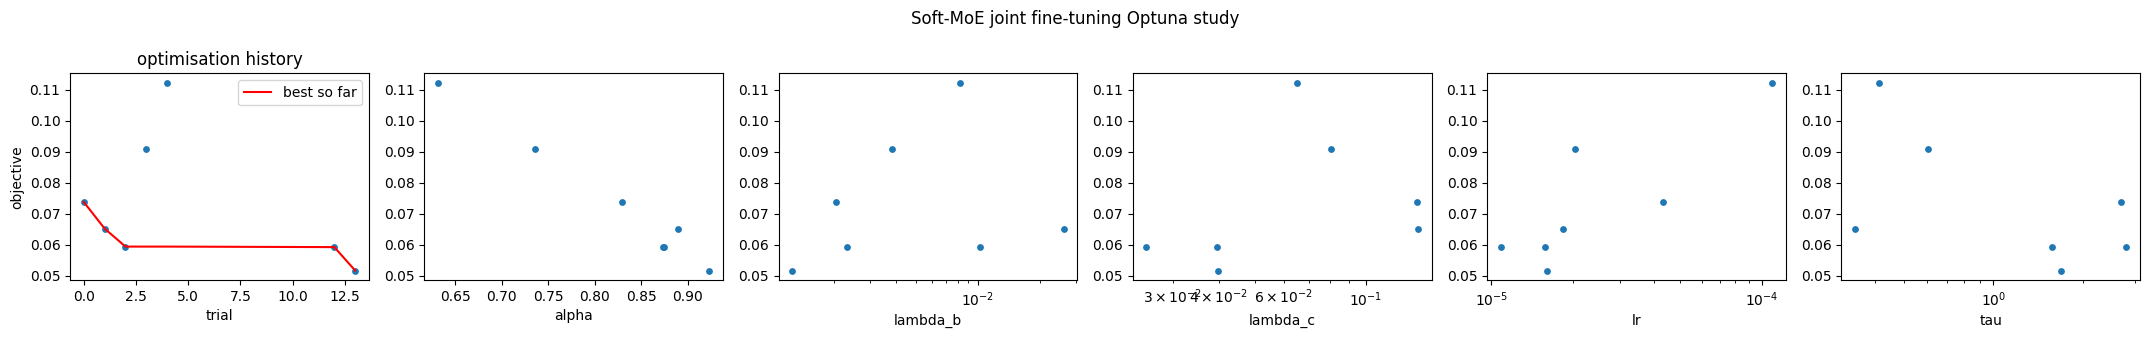

In [ ]:
# ============================================================
# Optuna: tune the joint fine-tuning learning rate, temperature tau,
# classification weight lambda_c, balance weight lambda_b, and the
# reconstruction-loss weighting (alpha, mixing L1 vs SSIM). Every trial
# starts from the SAME post-warmup checkpoint (never random), trains a few
# epochs with the trial's hyperparameters, and is pruned early if it either
# scores badly OR shows routing collapse (one branch's average weight
# above 0.9 or below 0.02) -- a config that collapses routing after a
# couple epochs is not going to recover, so there's no reason to keep
# spending budget on it.
# ============================================================

import optuna

N_MOE_OPTUNA_TRIALS = 15
MOE_OPTUNA_EPOCHS = 3
MOE_OPTUNA_BATCH_SIZE = 64

MOE_OPTUNA_BEST_PATH = os.path.join(MOE_RESULTS_DIR, 'moe_optuna_best.json')


def moe_objective(trial):
    lr = trial.suggest_float('lr', 1e-5, 5e-4, log=True)   # smaller than warm-up's LR, per the assignment
    tau = trial.suggest_float('tau', 0.3, 3.0, log=True)
    alpha = trial.suggest_float('alpha', 0.5, 0.95)
    lambda_c = trial.suggest_float('lambda_c', 0.02, 0.5, log=True)
    lambda_b = trial.suggest_float('lambda_b', 0.001, 0.1, log=True)

    set_seed(SEED)
    moe = build_soft_moe(temperature=tau)
    warmup_ckpt = torch.load(find_moe_file('moe_postwarmup.pt'), map_location=DEVICE)
    moe.load_state_dict(warmup_ckpt['model_state'])
    moe.temperature = tau
    moe.set_experts_trainable(True)
    optimizer = torch.optim.Adam(moe.parameters(), lr=lr)

    train_loader = make_loader(moe_train_ds, MOE_OPTUNA_BATCH_SIZE, shuffle=False, drop_last=True)
    val_loader = make_loader(val_ds, MOE_OPTUNA_BATCH_SIZE, shuffle=False, drop_last=False)

    best_val = float('inf')
    for epoch in range(MOE_OPTUNA_EPOCHS):
        moe.train()
        for batch in train_loader:
            clean = batch['clean'].to(DEVICE)
            corrupted = batch['corrupted'].to(DEVICE)
            labels = batch['label'].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            x_hat, w, logits = moe(corrupted, return_weights=True)
            loss, parts = moe_loss(x_hat, clean, w, logits, labels, alpha, lambda_c, lambda_b)
            loss.backward()
            optimizer.step()

        moe.eval()
        with torch.no_grad():
            val_total, val_n = 0.0, 0
            weight_sum = torch.zeros(4, device=DEVICE)
            for batch in val_loader:
                clean = batch['clean'].to(DEVICE)
                corrupted = batch['corrupted'].to(DEVICE)
                labels = batch['label'].to(DEVICE)
                x_hat, w, logits = moe(corrupted, return_weights=True)
                loss, parts = moe_loss(x_hat, clean, w, logits, labels, alpha, lambda_c, lambda_b)
                val_total += loss.item() * clean.size(0)
                val_n += clean.size(0)
                weight_sum += w.sum(dim=0)
        val_loss = val_total / max(val_n, 1)
        avg_w = (weight_sum / val_n).cpu().numpy()
        best_val = min(best_val, val_loss)

        # routing-collapse pruning: a branch stuck near 0 or near 1 this
        # early is not something 1-2 more epochs will fix
        collapsed = bool(avg_w.min() < 0.02 or avg_w.max() > 0.9)
        if collapsed:
            print(f'  trial {trial.number} epoch {epoch}: routing collapse detected {avg_w} -- pruning')
            raise optuna.TrialPruned()

        trial.report(val_loss, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return best_val


if os.path.exists(MOE_OPTUNA_BEST_PATH):
    with open(MOE_OPTUNA_BEST_PATH) as f:
        MOE_BEST_PARAMS = json.load(f)['best_params']
    print('Reusing saved joint fine-tuning Optuna result from Drive:')
    print(MOE_BEST_PARAMS)
else:
    moe_study = optuna.create_study(direction='minimize',
                                     sampler=optuna.samplers.TPESampler(seed=SEED),
                                     pruner=optuna.pruners.MedianPruner(n_warmup_steps=1))
    moe_study.optimize(moe_objective, n_trials=N_MOE_OPTUNA_TRIALS)

    print('Completed trials:', len([t for t in moe_study.trials if t.state == optuna.trial.TrialState.COMPLETE]))
    print('Pruned trials (incl. routing collapse):',
          len([t for t in moe_study.trials if t.state == optuna.trial.TrialState.PRUNED]))
    print('Best val loss:', moe_study.best_trial.value)
    print('Best hyperparameters:', moe_study.best_trial.params)

    with open(MOE_OPTUNA_BEST_PATH, 'w') as f:
        json.dump({'best_value': moe_study.best_trial.value, 'best_params': moe_study.best_trial.params}, f, indent=2)
    with open(os.path.join(MOE_RESULTS_DIR, 'moe_optuna_all_trials.json'), 'w') as f:
        json.dump([{'number': t.number, 'value': t.value, 'params': t.params, 'state': str(t.state)}
                   for t in moe_study.trials], f, indent=2)

    MOE_BEST_PARAMS = moe_study.best_trial.params

# Optuna summary plots from the saved trial log
def plot_optuna_trials(json_path, title, save_path):
    """Optimisation history and objective vs each hyperparameter, from the saved trial log."""
    if not os.path.exists(json_path):
        print('No trial log found at', json_path); return
    with open(json_path) as f:
        trials = json.load(f)
    done = sorted([t for t in trials if 'COMPLETE' in t['state']], key=lambda t: t['number'])
    print(f"{title}: {len(trials)} trials ({len(done)} complete, {sum('PRUNED' in t['state'] for t in trials)} pruned, "
          'pruning includes routing collapse)')
    params = sorted({k for t in done for k in t['params']})
    fig, axes = plt.subplots(1, 1 + len(params), figsize=(3.6 * (1 + len(params)), 3.4))
    vals = [t['value'] for t in done]
    axes[0].scatter([t['number'] for t in done], vals, s=15)
    axes[0].plot([t['number'] for t in done], np.minimum.accumulate(vals), 'r-', label='best so far')
    axes[0].set_xlabel('trial'); axes[0].set_ylabel('objective'); axes[0].set_title('optimisation history'); axes[0].legend()
    for ax, p in zip(axes[1:], params):
        ax.scatter([t['params'][p] for t in done], vals, s=15); ax.set_xlabel(p)
        if p in ('lr', 'tau', 'lambda_c', 'lambda_b'):
            ax.set_xscale('log')
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches='tight'); plt.show()

print('Search space: lr [1e-5, 5e-4] log | tau [0.3, 3.0] log | alpha [0.5, 0.95] | lambda_c [0.02, 0.5] log | lambda_b [0.001, 0.1] log')
plot_optuna_trials(os.path.join(MOE_RESULTS_DIR, 'moe_optuna_all_trials.json'), 'Soft-MoE joint fine-tuning Optuna study',
                   os.path.join(MOE_RESULTS_DIR, 'moe_optuna_plots.png'))

## 14. Joint fine-tuning (resumable)
Unfreezes the experts and trains gate + all 3 experts together at the Optuna-selected (smaller) learning rate. Saves a qualitative snapshot every 5 epochs (image + routing weights) and re-checks for routing collapse every 5 epochs.

Resuming joint fine-tuning from /content/drive/MyDrive/task3_artifacts/checkpoints/moe_joint_last.pt, epoch 61, best_val_loss 0.0491
✅ Joint fine-tuning already complete (epoch 60/60). Skipping.
Loaded best joint-fine-tuned MoE, val_loss = 0.04909635497176129
Warm-up LR 0.001 (experts frozen) -> joint fine-tuning LR 1.61e-05 (all parameters)


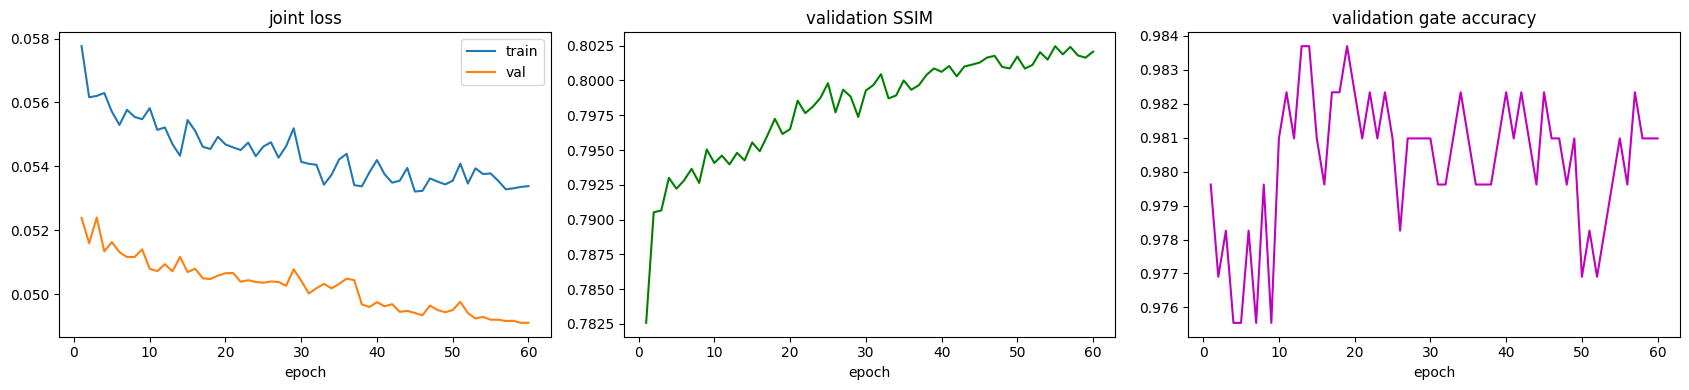

In [ ]:
# ============================================================
# Joint fine-tuning: unfreeze the experts, train gate + all 3 experts
# together with the Optuna-selected hyperparameters, starting from the
# post-warmup checkpoint. Resumable via Drive, like every other training
# loop in this project.
# ============================================================

MOE_FINAL_EPOCHS = 60
MOE_PATIENCE = 15
MOE_SNAPSHOT_EVERY = 5
MOE_DIAGNOSTIC_EVERY = 5
MOE_BATCH_SIZE = 64
MOE_CKPT_NAME = 'moe_joint_best.pt'
MOE_CKPT_LAST_NAME = 'moe_joint_last.pt'

moe_lr = MOE_BEST_PARAMS['lr']
moe_tau = MOE_BEST_PARAMS['tau']
moe_alpha = MOE_BEST_PARAMS['alpha']
moe_lambda_c = MOE_BEST_PARAMS['lambda_c']
moe_lambda_b = MOE_BEST_PARAMS['lambda_b']

set_seed(SEED)
moe = build_soft_moe(temperature=moe_tau)
warmup_ckpt = torch.load(find_moe_file('moe_postwarmup.pt'), map_location=DEVICE)
moe.load_state_dict(warmup_ckpt['model_state'])
moe.temperature = moe_tau
moe.set_experts_trainable(True)
optimizer = torch.optim.Adam(moe.parameters(), lr=moe_lr)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

start_epoch = 1
best_val_loss = float('inf')
epochs_no_improve = 0
history = []

resume_path = find_moe_file(MOE_CKPT_LAST_NAME)
if resume_path is not None:
    ckpt = torch.load(resume_path, map_location=DEVICE)
    moe.load_state_dict(ckpt['model_state'])
    optimizer.load_state_dict(ckpt['optimizer_state'])
    moe.temperature = ckpt['temperature']
    start_epoch = ckpt['epoch'] + 1
    best_val_loss = ckpt['best_val_loss']
    epochs_no_improve = ckpt['epochs_no_improve']
    history = ckpt.get('history', [])
    print(f'Resuming joint fine-tuning from {resume_path}, epoch {start_epoch}, best_val_loss {best_val_loss:.4f}')
else:
    print('Starting joint fine-tuning fresh from the post-warmup checkpoint.')

train_loader = make_loader(moe_train_ds, MOE_BATCH_SIZE, shuffle=False, drop_last=True)
val_loader = make_loader(val_ds, MOE_BATCH_SIZE, shuffle=False, drop_last=False)

if start_epoch > MOE_FINAL_EPOCHS:
    print(f'\u2705 Joint fine-tuning already complete (epoch {start_epoch-1}/{MOE_FINAL_EPOCHS}). Skipping.')

for epoch in range(start_epoch, MOE_FINAL_EPOCHS + 1):
    t0 = time.time()
    moe.train()
    train_total, train_n = 0.0, 0
    for batch in train_loader:
        clean = batch['clean'].to(DEVICE)
        corrupted = batch['corrupted'].to(DEVICE)
        labels = batch['label'].to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        x_hat, w, logits = moe(corrupted, return_weights=True)
        loss, parts = moe_loss(x_hat, clean, w, logits, labels, moe_alpha, moe_lambda_c, moe_lambda_b)
        loss.backward()
        optimizer.step()
        train_total += loss.item() * clean.size(0)
        train_n += clean.size(0)
    train_loss = train_total / max(train_n, 1)

    moe.eval()
    with torch.no_grad():
        val_total, val_n, val_correct = 0.0, 0, 0
        val_l1_sum, val_ssim_sum = 0.0, 0.0
        for batch in val_loader:
            clean = batch['clean'].to(DEVICE)
            corrupted = batch['corrupted'].to(DEVICE)
            labels = batch['label'].to(DEVICE)
            x_hat, w, logits = moe(corrupted, return_weights=True)
            loss, parts = moe_loss(x_hat, clean, w, logits, labels, moe_alpha, moe_lambda_c, moe_lambda_b)
            bs = clean.size(0)
            val_total += loss.item() * bs
            val_n += bs
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_l1_sum += parts['l1'].item() * bs
            val_ssim_sum += parts['ssim'].item() * bs
    val_loss = val_total / max(val_n, 1)
    val_acc = val_correct / max(val_n, 1)

    scheduler.step(val_loss)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                     'val_gate_acc': val_acc, 'val_l1': val_l1_sum / max(val_n, 1),
                     'val_ssim': val_ssim_sum / max(val_n, 1), 'time_s': time.time() - t0})
    print(f'[joint] epoch {epoch:03d} | train {train_loss:.4f} | val {val_loss:.4f} '
          f'(l1 {val_l1_sum/max(val_n,1):.4f}, ssim {val_ssim_sum/max(val_n,1):.4f}, gate_acc {val_acc:.3f}) '
          f'| lr {optimizer.param_groups[0]["lr"]:.2e} | {time.time()-t0:.1f}s')

    if epoch % MOE_SNAPSHOT_EVERY == 0 or epoch == 1:
        os.makedirs(MOE_SNAPSHOT_DIR, exist_ok=True)
        sample_ds = PetManifestDataset(val_manifest[:4])
        fig, axes = plt.subplots(4, 3, figsize=(8, 10))
        with torch.no_grad():
            for i in range(4):
                item = sample_ds[i]
                c = item['clean'].unsqueeze(0).to(DEVICE)
                x = item['corrupted'].unsqueeze(0).to(DEVICE)
                xh, w, _ = moe(x, return_weights=True)
                for col, img in enumerate([c[0], x[0], xh[0].clamp(0, 1)]):
                    axes[i, col].imshow(img.cpu().permute(1, 2, 0).numpy())
                    axes[i, col].axis('off')
                    if i == 0:
                        axes[i, col].set_title(['clean', 'corrupted', 'moe restored'][col])
                axes[i, 0].set_ylabel('w=' + ','.join(f'{v:.2f}' for v in w[0].cpu().numpy()), fontsize=7)
        fig.suptitle(f'joint fine-tune -- epoch {epoch}')
        plt.tight_layout()
        snap_path = os.path.join(MOE_SNAPSHOT_DIR, f'moe_epoch{epoch:03d}.png')
        plt.savefig(snap_path, dpi=90, bbox_inches='tight')
        plt.close(fig)
        print(f'  saved snapshot: {snap_path}')

    if epoch % MOE_DIAGNOSTIC_EVERY == 0:
        check_routing_collapse(moe, val_loader)

    improved = val_loss < best_val_loss - 1e-5
    if improved:
        best_val_loss = val_loss
        epochs_no_improve = 0
        save_checkpoint({'model_state': moe.state_dict(), 'temperature': moe_tau,
                          'epoch': epoch, 'val_loss': best_val_loss}, MOE_CKPT_NAME)
        if epoch == start_epoch:
            verify_checkpoint(MOE_CKPT_NAME)
    else:
        epochs_no_improve += 1

    save_checkpoint({'model_state': moe.state_dict(), 'optimizer_state': optimizer.state_dict(),
                      'temperature': moe_tau, 'epoch': epoch, 'best_val_loss': best_val_loss,
                      'epochs_no_improve': epochs_no_improve, 'history': history}, MOE_CKPT_LAST_NAME)

    if epochs_no_improve >= MOE_PATIENCE:
        print(f'Early stopping at epoch {epoch} (no improvement for {MOE_PATIENCE} epochs).')
        break

with open(os.path.join(MOE_RESULTS_DIR, 'moe_training_history.json'), 'w') as f:
    json.dump(history, f, indent=2)

# reload best checkpoint
best_path = find_moe_file(MOE_CKPT_NAME)
best_ckpt = torch.load(best_path, map_location=DEVICE)
moe = build_soft_moe(temperature=best_ckpt['temperature'])
moe.load_state_dict(best_ckpt['model_state'])
moe.eval()
print('Loaded best joint-fine-tuned MoE, val_loss =', best_ckpt['val_loss'])

# Joint fine-tuning curves
import pandas as pd
print(f'Warm-up LR {WARMUP_LR:g} (experts frozen) -> joint fine-tuning LR {moe_lr:.2e} (all parameters)')
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(h['epoch'], h['train_loss'], label='train'); axes[0].plot(h['epoch'], h['val_loss'], label='val'); axes[0].set_title('joint loss'); axes[0].legend()
axes[1].plot(h['epoch'], h['val_ssim'], 'g'); axes[1].set_title('validation SSIM')
axes[2].plot(h['epoch'], h['val_gate_acc'], 'm'); axes[2].set_title('validation gate accuracy')
for a in axes: a.set_xlabel('epoch')
plt.tight_layout(); plt.savefig(os.path.join(MOE_RESULTS_DIR, 'moe_training_curves.png'), dpi=120, bbox_inches='tight'); plt.show()

## 15. Gating behavior analysis
Average expert weights by true corruption type and severity, a routing heatmap, an inactive/dominating-expert check, and specific examples where one expert dominates vs. where weights are spread across experts (by routing entropy) — everything the assignment's report requirements ask for.

Average expert weights by TRUE corruption type and severity
        ctype severity  w_clean  w_salt_pepper  w_gaussian_blur  w_occlusion
        clean       na 0.953887       0.001480         0.035151     0.009481
gaussian_blur     high 0.204630       0.000075         0.794375     0.000920
gaussian_blur      low 0.316704       0.000130         0.681468     0.001698
gaussian_blur   medium 0.211249       0.000080         0.787718     0.000952
    occlusion     high 0.119959       0.003094         0.006082     0.870865
    occlusion      low 0.260507       0.009850         0.014122     0.715521
    occlusion   medium 0.160457       0.005221         0.008270     0.826052
  salt_pepper     high 0.040468       0.958384         0.000131     0.001017
  salt_pepper      low 0.116819       0.880034         0.000301     0.002846
  salt_pepper   medium 0.044614       0.954034         0.000145     0.001206


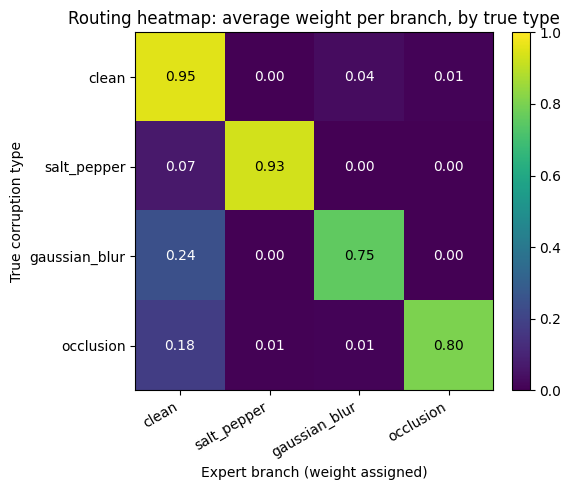

Saved routing heatmap to /content/drive/MyDrive/task3_artifacts/results/routing_heatmap.png

Inactive / dominating expert check -- whole test set
Average routing weight per branch (over the whole dataset):
  clean          0.2429
  salt_pepper    0.2812
  gaussian_blur  0.2328
  occlusion      0.2431

Dominant-branch weight, per true type (ideally near-diagonal: the branch matching the true
type should get the highest average weight for that type):
  true=clean          -> dominant branch = w_clean        (weight=0.954)
  true=salt_pepper    -> dominant branch = w_salt_pepper  (weight=0.931)
  true=gaussian_blur  -> dominant branch = w_gaussian_blur (weight=0.755)
  true=occlusion      -> dominant branch = w_occlusion    (weight=0.804)

4 examples where ONE expert dominates (low routing entropy)
ctype severity  w_clean  w_salt_pepper  w_gaussian_blur  w_occlusion  entropy
clean       na 0.995014       0.000845         0.002950     0.001191 0.036161
clean       na 0.994936       0.00096

In [ ]:
# ============================================================
# Gating behavior analysis, as required by the assignment:
#   - average expert weights for every true corruption type and severity
#   - examples where one expert dominates vs. weights are distributed
#   - a routing heatmap
#   - whether any expert is inactive, or dominates unrelated inputs
# ============================================================

@torch.no_grad()
def collect_routing_records(model, manifest, device=DEVICE):
    ds = PetManifestDataset(manifest)
    loader = make_loader(ds, 64, shuffle=False, drop_last=False)
    records = []
    idx_counter = 0
    for batch in loader:
        corrupted = batch['corrupted'].to(device)
        ctypes = batch['ctype']
        severities = batch.get('severity', ['na'] * len(ctypes))
        _, w, _ = model(corrupted, return_weights=True)
        w = w.cpu().numpy()
        for i in range(len(ctypes)):
            rec = {'idx': idx_counter, 'ctype': ctypes[i], 'severity': severities[i]}
            for j, name in enumerate(CORRUPTION_TYPES):
                rec[f'w_{name}'] = float(w[i, j])
            records.append(rec)
            idx_counter += 1
    return records


import pandas as pd

test_routing_records = collect_routing_records(moe, test_manifest)
routing_df = pd.DataFrame(test_routing_records)

print('=' * 74)
print('Average expert weights by TRUE corruption type and severity')
print('=' * 74)
weight_cols = [f'w_{n}' for n in CORRUPTION_TYPES]
summary = routing_df.groupby(['ctype', 'severity'])[weight_cols].mean().reset_index()
print(summary.to_string(index=False))
summary.to_csv(os.path.join(MOE_RESULTS_DIR, 'routing_weights_by_type_severity.csv'), index=False)

# ---- routing heatmap: rows = true type, columns = expert branch ----
heat = routing_df.groupby('ctype')[weight_cols].mean().reindex(CORRUPTION_TYPES)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(heat.values, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(CORRUPTION_TYPES, rotation=30, ha='right')
ax.set_yticks(range(4)); ax.set_yticklabels(CORRUPTION_TYPES)
ax.set_xlabel('Expert branch (weight assigned)')
ax.set_ylabel('True corruption type')
ax.set_title('Routing heatmap: average weight per branch, by true type')
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{heat.values[i,j]:.2f}', ha='center', va='center',
                 color='white' if heat.values[i, j] < 0.5 else 'black')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
heatmap_path = os.path.join(MOE_RESULTS_DIR, 'routing_heatmap.png')
plt.savefig(heatmap_path, dpi=120, bbox_inches='tight')
plt.show()
print('Saved routing heatmap to', heatmap_path)

# ---- inactive / dominating expert check (dataset-wide, and per true-type) ----
print('\n' + '=' * 74)
print('Inactive / dominating expert check -- whole test set')
print('=' * 74)
check_routing_collapse(moe, make_loader(test_ds, 64, shuffle=False, drop_last=False))

print('\nDominant-branch weight, per true type (ideally near-diagonal: the branch matching the true')
print('type should get the highest average weight for that type):')
for ctype in CORRUPTION_TYPES:
    row = heat.loc[ctype]
    dominant = row.idxmax()
    print(f'  true={ctype:14s} -> dominant branch = {dominant:14s} (weight={row[dominant]:.3f})')

# ---- dominant vs. distributed EXAMPLES ----
routing_df['entropy'] = -(routing_df[weight_cols].clip(1e-8, 1).apply(np.log) * routing_df[weight_cols]).sum(axis=1)
# low entropy = one branch dominates; high entropy (max = ln(4)=1.386) = weights spread out
sharp_examples = routing_df.nsmallest(4, 'entropy')
distributed_examples = routing_df.nlargest(4, 'entropy')

print('\n' + '=' * 74)
print('4 examples where ONE expert dominates (low routing entropy)')
print('=' * 74)
print(sharp_examples[['ctype', 'severity'] + weight_cols + ['entropy']].to_string(index=False))

print('\n' + '=' * 74)
print('4 examples where weights are DISTRIBUTED across experts (high routing entropy)')
print('=' * 74)
print(distributed_examples[['ctype', 'severity'] + weight_cols + ['entropy']].to_string(index=False))

routing_df.to_csv(os.path.join(MOE_RESULTS_DIR, 'routing_weights_per_sample.csv'), index=False)


## 15b. Visual gallery: actual images, not just tables
Renders real images for the dominant-vs-distributed examples above (with routing weight bars alongside each one, red = most-contributing expert), plus a side-by-side comparison of **corrupted → Task 2 hard-routed → Task 3 soft-MoE → clean** for one example per corruption type — the most direct way to see what joint training actually changed.

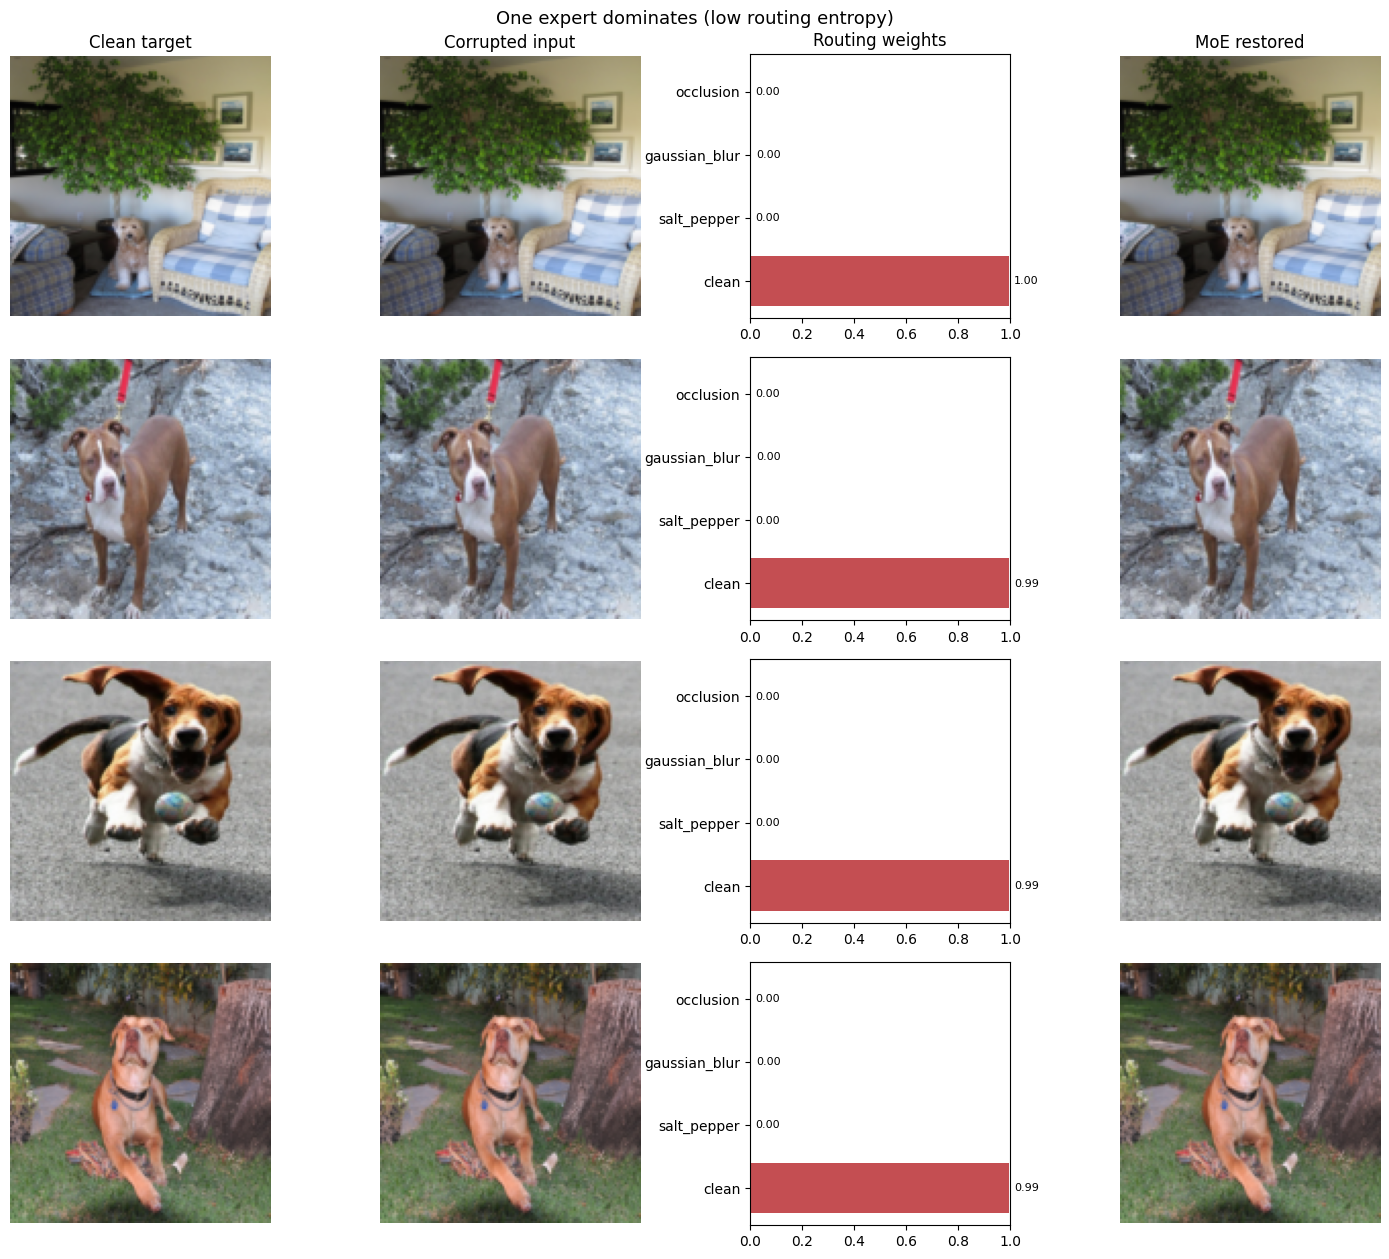

Saved to /content/drive/MyDrive/task3_artifacts/results/dominant_expert_examples.png


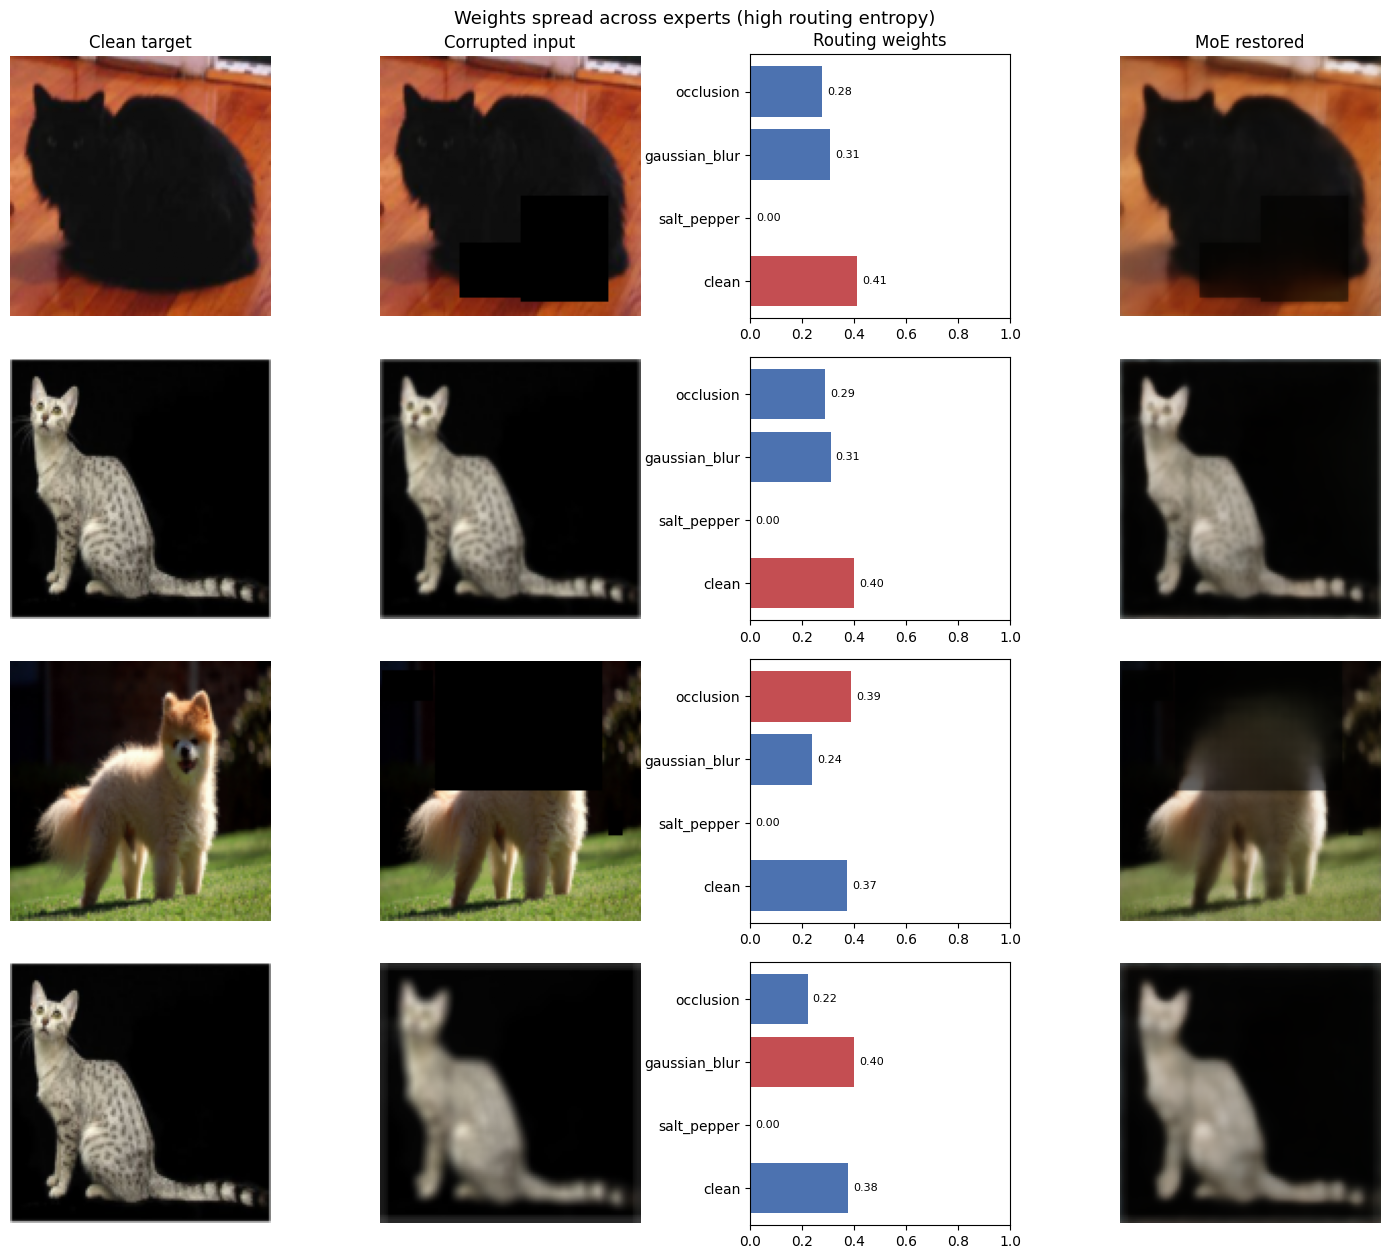

Saved to /content/drive/MyDrive/task3_artifacts/results/distributed_expert_examples.png


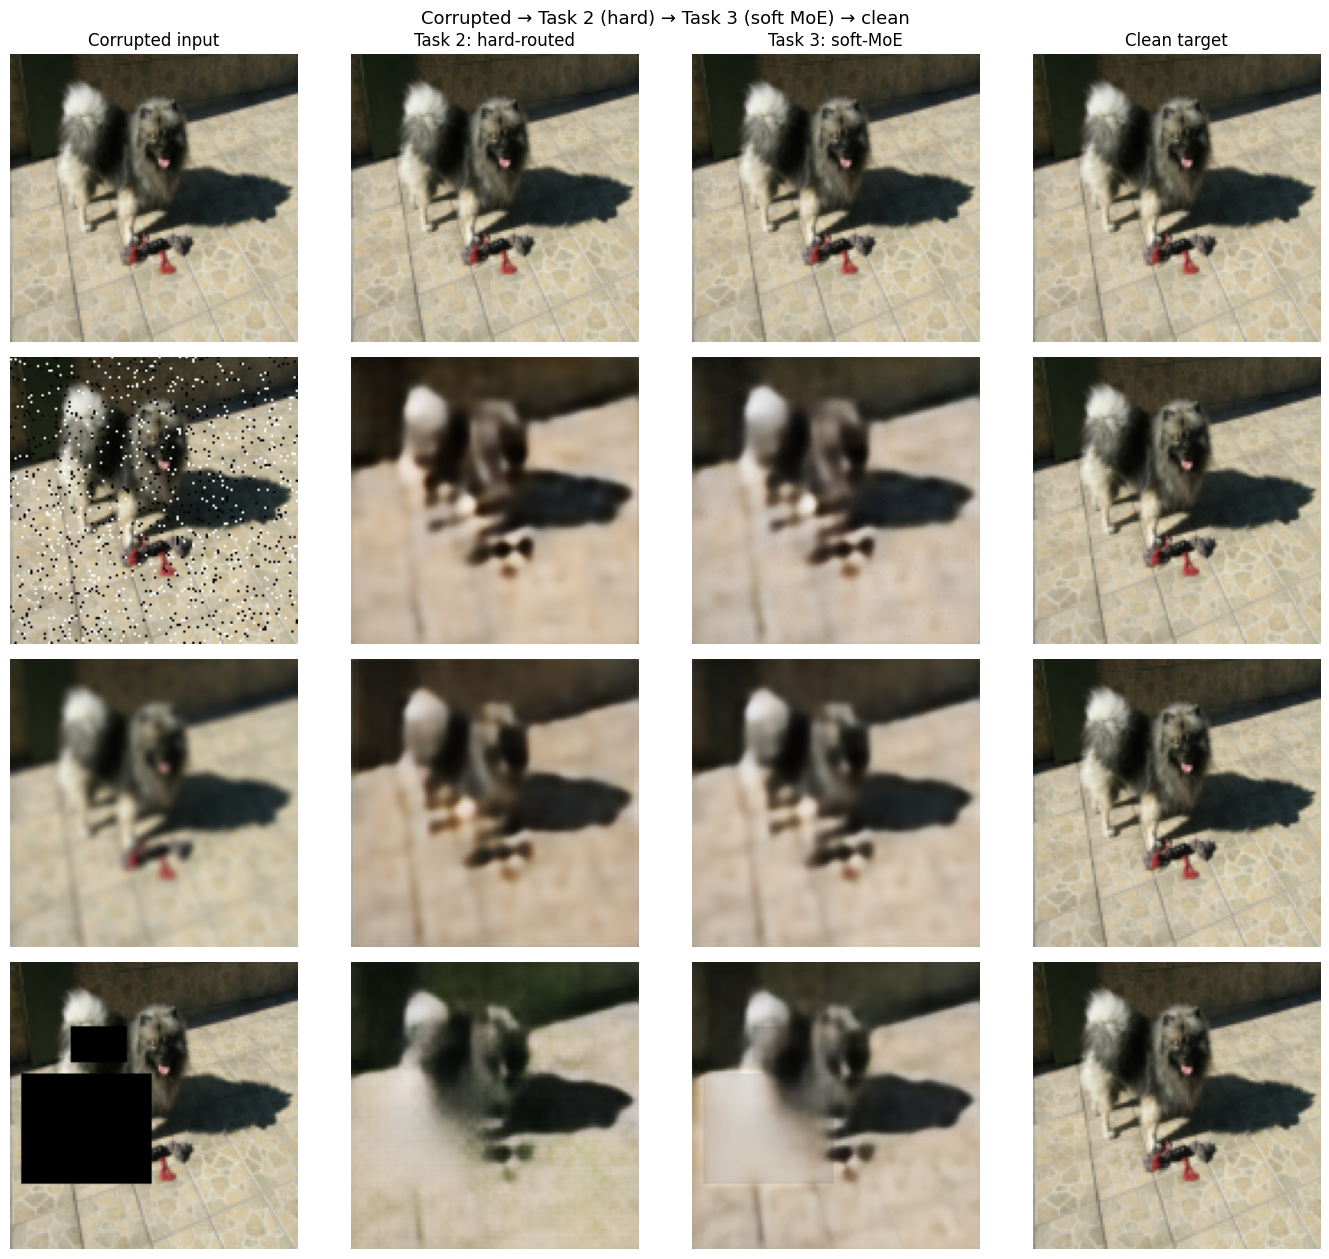

Saved to /content/drive/MyDrive/task3_artifacts/results/hard_vs_soft_comparison.png


In [ ]:
# ============================================================
# VISUAL results -- actual images, not just tables. The assignment asks
# you to "show examples" of dominant vs. distributed routing; this renders
# them as images with the routing weights drawn alongside each one.
# ============================================================

def show_routing_examples_visual(df_subset, title, save_name):
    n = len(df_subset)
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.2 * n))
    if n == 1:
        axes = axes[None, :]
    col_titles = ['Clean target', 'Corrupted input', 'Routing weights', 'MoE restored']

    with torch.no_grad():
        for row, (_, rec) in enumerate(df_subset.iterrows()):
            sample = test_ds[int(rec['idx'])]
            clean = sample['clean'].unsqueeze(0).to(DEVICE)
            corrupted = sample['corrupted'].unsqueeze(0).to(DEVICE)
            x_hat, w, _ = moe(corrupted, return_weights=True)
            w = w.squeeze(0).cpu().numpy()
            dominant_idx = int(w.argmax())

            axes[row, 0].imshow(clean[0].cpu().permute(1, 2, 0).numpy()); axes[row, 0].axis('off')
            axes[row, 0].set_ylabel(f"true={rec['ctype']}/{rec['severity']}", fontsize=8)
            axes[row, 1].imshow(corrupted[0].cpu().permute(1, 2, 0).numpy()); axes[row, 1].axis('off')

            axes[row, 2].barh(CORRUPTION_TYPES, w,
                               color=['#4C72B0' if i != dominant_idx else '#C44E52' for i in range(4)])
            axes[row, 2].set_xlim(0, 1)
            for i, v in enumerate(w):
                axes[row, 2].text(v + 0.02, i, f'{v:.2f}', va='center', fontsize=8)

            axes[row, 3].imshow(x_hat[0].clamp(0, 1).cpu().permute(1, 2, 0).numpy()); axes[row, 3].axis('off')

            if row == 0:
                for col in range(4):
                    axes[row, col].set_title(col_titles[col])

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    out_path = os.path.join(MOE_RESULTS_DIR, save_name)
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()
    print('Saved to', out_path)


# 4 lowest-entropy (one expert dominates) and 4 highest-entropy (spread out)
show_routing_examples_visual(sharp_examples, 'One expert dominates (low routing entropy)',
                              'dominant_expert_examples.png')
show_routing_examples_visual(distributed_examples, 'Weights spread across experts (high routing entropy)',
                              'distributed_expert_examples.png')


# ---- side-by-side: corrupted -> Task 2 hard-routed -> Task 3 soft-MoE -> clean ----
@torch.no_grad()
def show_hard_vs_soft_comparison(indices, save_name='hard_vs_soft_comparison.png'):
    n = len(indices)
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.2 * n))
    if n == 1:
        axes = axes[None, :]
    col_titles = ['Corrupted input', 'Task 2: hard-routed', 'Task 3: soft-MoE', 'Clean target']

    for row, idx in enumerate(indices):
        sample = test_ds[idx]
        clean = sample['clean'].unsqueeze(0).to(DEVICE)
        corrupted = sample['corrupted'].unsqueeze(0).to(DEVICE)
        true_label = torch.tensor([sample['label']], device=DEVICE)
        true_name = CORRUPTION_TYPES[sample['label']]

        # Task 2 hard routing: classifier argmax -> single expert (or identity if predicted clean)
        pred = task2_classifier(corrupted).argmax(1).item()
        pred_name = CORRUPTION_TYPES[pred]
        hard_out = corrupted if pred_name == 'clean' else task2_specialists[pred_name](corrupted)

        # Task 3 soft MoE
        soft_out, w, _ = moe(corrupted, return_weights=True)

        imgs = [corrupted[0], hard_out[0].clamp(0, 1), soft_out[0].clamp(0, 1), clean[0]]
        for col, img in enumerate(imgs):
            axes[row, col].imshow(img.cpu().permute(1, 2, 0).numpy())
            axes[row, col].axis('off')
            if row == 0:
                axes[row, col].set_title(col_titles[col])
        axes[row, 0].set_ylabel(f'true={true_name}', fontsize=8)

    fig.suptitle('Corrupted \u2192 Task 2 (hard) \u2192 Task 3 (soft MoE) \u2192 clean', fontsize=13)
    plt.tight_layout()
    out_path = os.path.join(MOE_RESULTS_DIR, save_name)
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()
    print('Saved to', out_path)


comparison_indices = []
for ctype in CORRUPTION_TYPES:
    matches = [i for i, e in enumerate(test_manifest) if e['ctype'] == ctype]
    if matches:
        comparison_indices.append(matches[len(matches) // 2])
show_hard_vs_soft_comparison(comparison_indices)


## 16. Final reconstruction evaluation, vs. Task 2's hard routing
Reconstruction quality by type/severity, and — if Task 2's hard-routing metrics are found on Drive — a direct SSIM comparison showing where soft routing helps (ambiguous/boundary cases) vs. where hard routing's full-strength single expert already wins.

In [ ]:
# ============================================================
# Final reconstruction quality, and a direct comparison against Task 2's
# hard-routing system on the same test set.
# ============================================================

def psnr_per_sample(x_hat, x, eps=1e-8):
    mse = F.mse_loss(x_hat, x, reduction='none').mean(dim=[1, 2, 3])
    return 10.0 * torch.log10(1.0 / (mse + eps))


@torch.no_grad()
def evaluate_moe(model, loader, device=DEVICE):
    model.eval()
    records = []
    for batch in loader:
        clean = batch['clean'].to(device)
        corrupted = batch['corrupted'].to(device)
        ctypes = batch['ctype']
        severities = batch.get('severity', ['na'] * len(ctypes))
        x_hat, w, _ = model(corrupted, return_weights=True)
        l1_ps = F.l1_loss(x_hat, clean, reduction='none').mean(dim=[1, 2, 3])
        ssim_ps = ssim_metric(x_hat, clean, data_range=1.0, size_average=False)
        psnr_ps = psnr_per_sample(x_hat, clean)
        for i in range(clean.size(0)):
            records.append({'ctype': ctypes[i], 'severity': severities[i],
                             'l1': l1_ps[i].item(), 'ssim': ssim_ps[i].item(), 'psnr': psnr_ps[i].item()})
    return records


moe_test_loader = make_loader(test_ds, batch_size=64, shuffle=False, drop_last=False)
moe_records = evaluate_moe(moe, moe_test_loader)
moe_df = pd.DataFrame(moe_records)
moe_summary = moe_df.groupby(['ctype', 'severity'])[['l1', 'ssim', 'psnr']].mean().reset_index()

print('=' * 74)
print('Soft MoE (Task 3) -- reconstruction quality by type/severity')
print('=' * 74)
print(moe_summary.to_string(index=False))
moe_summary.to_csv(os.path.join(MOE_RESULTS_DIR, 'moe_test_metrics.csv'), index=False)

print(f'\nOverall (all conditions pooled): l1={moe_df["l1"].mean():.4f} '
      f'ssim={moe_df["ssim"].mean():.4f} psnr={moe_df["psnr"].mean():.4f}')

# ---- comparison against Task 2's hard (predicted) routing, if available ----
hard_csv_path = os.path.join(RESULTS_DIR, 'predicted_routing_metrics.csv')
if os.path.exists(hard_csv_path):
    hard_df = pd.read_csv(hard_csv_path)
    merged = moe_summary.merge(hard_df, on=['ctype', 'severity'], suffixes=('_moe', '_hard'))
    merged['ssim_delta'] = merged['ssim_moe'] - merged['ssim_hard']
    print('\n' + '=' * 74)
    print('Soft MoE vs. Task 2 hard-routing (predicted) -- SSIM comparison')
    print('=' * 74)
    print(merged[['ctype', 'severity', 'ssim_hard', 'ssim_moe', 'ssim_delta']].to_string(index=False))
    merged.to_csv(os.path.join(MOE_RESULTS_DIR, 'moe_vs_hard_routing_comparison.csv'), index=False)
else:
    print('\nTask 2\'s predicted_routing_metrics.csv not found -- skipping direct comparison '
          '(re-run Task 2\'s hard-routing evaluation cell first if you want this table).')

# Full comparison: Task 1 universal AE vs Task 2 hard routing (oracle and predicted) vs Task 3 soft MoE
_tabs = {'task1': '/content/drive/MyDrive/universal_restoration/results/test_metrics_by_type_severity.csv',
         'task2_oracle': os.path.join(RESULTS_DIR, 'oracle_routing_metrics.csv'),
         'task2_predicted': os.path.join(RESULTS_DIR, 'predicted_routing_metrics.csv')}
full = moe_summary.rename(columns={m: f'{m}_task3' for m in ['l1', 'ssim', 'psnr']})
for name, path in _tabs.items():
    if os.path.exists(path):
        full = full.merge(pd.read_csv(path).rename(columns={m: f'{m}_{name}' for m in ['l1', 'ssim', 'psnr']}), on=['ctype', 'severity'])
for m in ['ssim', 'psnr']:
    print(f'\n=== {m.upper()} ===')
    print(full[['ctype', 'severity'] + [c for c in full.columns if c.startswith(m + '_')]].round(4).to_string(index=False))
full.to_csv(os.path.join(MOE_RESULTS_DIR, 'task1_task2_task3_comparison.csv'), index=False)

Soft MoE (Task 3) -- reconstruction quality by type/severity
        ctype severity       l1     ssim      psnr
        clean       na 0.001852 0.997437 57.298935
gaussian_blur     high 0.042052 0.716455 24.710142
gaussian_blur      low 0.033221 0.827485 26.732990
gaussian_blur   medium 0.038994 0.756455 25.400853
    occlusion     high 0.060595 0.655900 20.359450
    occlusion      low 0.038876 0.802665 24.228180
    occlusion   medium 0.048879 0.726198 22.276360
  salt_pepper     high 0.044788 0.696825 24.306609
  salt_pepper      low 0.039381 0.744686 25.155772
  salt_pepper   medium 0.043260 0.715362 24.567182

Overall (all conditions pooled): l1=0.0392 ssim=0.7639 psnr=27.5036

Soft MoE vs. Task 2 hard-routing (predicted) -- SSIM comparison
        ctype severity  ssim_hard  ssim_moe  ssim_delta
        clean       na   0.997695  0.997437   -0.000257
gaussian_blur     high   0.695147  0.716455    0.021308
gaussian_blur      low   0.755408  0.827485    0.072077
gaussian_blur   medi

## 16b. Failure cases (lowest SSIM per corruption type, with error maps)

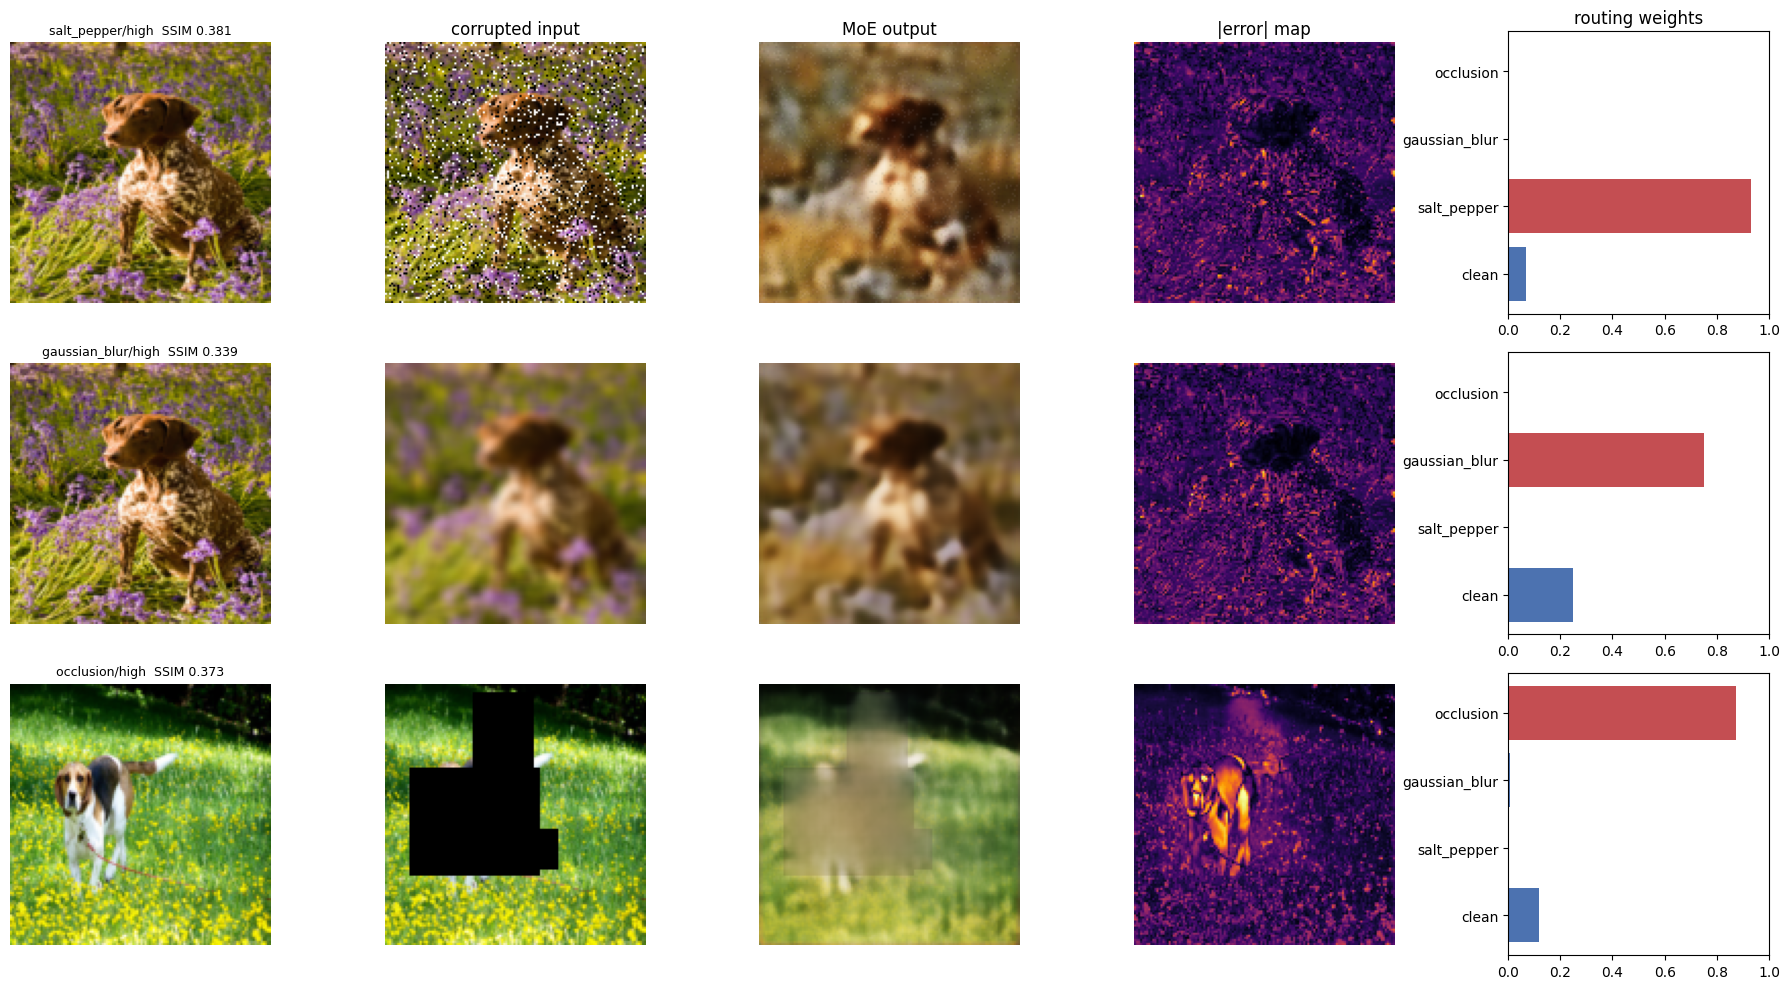

In [ ]:
_fail = [int(moe_df[moe_df['ctype'] == c]['ssim'].idxmin()) for c in ['salt_pepper', 'gaussian_blur', 'occlusion']]
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
with torch.no_grad():
    for r, i in enumerate(_fail):
        s = test_ds[i]
        clean, x = s['clean'].to(DEVICE), s['corrupted'].unsqueeze(0).to(DEVICE)
        x_hat, w, _ = moe(x, return_weights=True)
        w = w[0].cpu().numpy()
        err = (x_hat[0].clamp(0, 1) - clean).abs().mean(0).cpu().numpy()
        for c, img in enumerate([clean, x[0], x_hat[0].clamp(0, 1)]):
            axes[r, c].imshow(img.cpu().permute(1, 2, 0).numpy()); axes[r, c].axis('off')
        axes[r, 3].imshow(err, cmap='inferno', vmin=0, vmax=0.5); axes[r, 3].axis('off')
        axes[r, 4].barh(CORRUPTION_TYPES, w, color=['#C44E52' if k == w.argmax() else '#4C72B0' for k in range(4)]); axes[r, 4].set_xlim(0, 1)
        axes[r, 0].set_title(f"{s['ctype']}/{s['severity']}  SSIM {moe_df.loc[i, 'ssim']:.3f}", fontsize=9)
for c, t in enumerate(['clean target', 'corrupted input', 'MoE output', '|error| map', 'routing weights']):
    if c: axes[0, c].set_title(t)
plt.tight_layout(); plt.savefig(os.path.join(MOE_RESULTS_DIR, 'moe_failure_cases.png'), dpi=120, bbox_inches='tight'); plt.show()

**Failure cases and limitations.**
* Heavy occlusion stays the hardest case: the occlusion expert fills large masks with smooth, low-detail content.
* On mild blur and occlusion, the gate splits weight between the identity branch and the expert (see the routing table). The output is then a blend that keeps part of the corruption, for example faint rectangles.
* All three experts run on every image, roughly 3× the cost of hard routing.
* The gate is trained only on single corruptions, so behaviour on mixed corruptions is not guaranteed.
* No expert is inactive and none dominates unrelated inputs: every branch's average weight is about 0.23–0.28, and each true type is routed mainly to its own expert (see the routing heatmap).

## 17. Export to ONNX for the *Soft Mixture-of-Experts Restoration* app workspace
The **entire** pipeline (gate + all 3 experts + the weighted combination) exports as a single ONNX graph with two outputs: the restored image and the 4 routing weights — matching the assignment's required app display in one inference call.

In [ ]:
# ============================================================
# Export the COMPLETE soft mixture-of-experts inference pipeline -- gate,
# all 3 experts, and the weighted combination -- as a single ONNX graph,
# for the "Soft Mixture-of-Experts Restoration" app workspace.
# ============================================================

moe.eval().cpu()
dummy_img = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
moe_onnx_path = os.path.join(MOE_ONNX_DIR, 'soft_moe_restoration.onnx')

# Export with return_weights=True baked in, so the app gets BOTH the
# restored image and the 4 routing weights from one graph/one inference
# call (matches the assignment's display requirements directly).
class MoEExportWrapper(nn.Module):
    def __init__(self, moe_model):
        super().__init__()
        self.moe_model = moe_model

    def forward(self, x):
        x_hat, w, _ = self.moe_model(x, return_weights=True)
        return x_hat, w


export_model = MoEExportWrapper(moe)
torch.onnx.export(
    export_model, dummy_img, moe_onnx_path,
    input_names=['corrupted_image'], output_names=['restored_image', 'routing_weights'],
    dynamic_axes={'corrupted_image': {0: 'batch'}, 'restored_image': {0: 'batch'}, 'routing_weights': {0: 'batch'}},
    opset_version=17, dynamo=False,
)
moe.to(DEVICE)

import onnx
onnx.checker.check_model(onnx.load(moe_onnx_path))
print('Soft MoE pipeline exported and validated at:', moe_onnx_path)

with open(os.path.join(MOE_ONNX_DIR, 'app_config.json'), 'w') as f:
    json.dump({
        'img_size': IMG_SIZE,
        'input_range': '[0,1] float32, CHW, RGB',
        'class_names': CORRUPTION_TYPES,
        'temperature': moe.temperature,
        'outputs': {'restored_image': '(B,3,H,W) reconstructed image',
                    'routing_weights': '(B,4) softmax weights [clean, salt_pepper, gaussian_blur, occlusion]'},
        'onnx_file': 'soft_moe_restoration.onnx',
    }, f, indent=2)

import onnxruntime as ort
sess = ort.InferenceSession(moe_onnx_path, providers=['CPUExecutionProvider'])
t0 = time.time()
restored, weights = sess.run(None, {'corrupted_image': dummy_img.numpy()})
inference_ms = (time.time() - t0) * 1000
print(f'ONNX Runtime check OK: restored {restored.shape}, weights {weights.shape} '
      f'(sums to {weights.sum():.3f}), inference time {inference_ms:.1f} ms')

# Verify ONNX Runtime outputs against PyTorch on real test images
_x = torch.stack([test_ds[i]['corrupted'] for i in range(0, 640, 20)])
moe.eval().cpu()
with torch.no_grad():
    _pt_img, _pt_w, _ = moe(_x, return_weights=True)
moe.to(DEVICE)
_ox_img, _ox_w = sess.run(None, {'corrupted_image': _x.numpy()})
print(f'restored image: max |diff| = {np.abs(_pt_img.numpy() - _ox_img).max():.2e} | '
      f'routing weights: max |diff| = {np.abs(_pt_w.numpy() - _ox_w).max():.2e}')

/tmp/ipykernel_496/2764576224.py:25: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Soft MoE pipeline exported and validated at: /content/drive/MyDrive/task3_artifacts/onnx_export/soft_moe_restoration.onnx
ONNX Runtime check OK: restored (1, 3, 128, 128), weights (1, 4) (sums to 1.000), inference time 267.4 ms
restored image: max |diff| = 4.77e-07 | routing weights: max |diff| = 2.38e-07


## 18. Final test: reload from Drive and preview the app
Reloads the joint-fine-tuned model strictly from its saved Drive checkpoint and previews exactly what the app should show: the clean target, corrupted input, all 4 routing weights as a bar chart (red = most-contributing expert), inference time, and the restored image.

Loaded Soft MoE fresh from /content/drive/MyDrive/task3_artifacts/checkpoints/moe_joint_best.pt (val_loss=0.0491, temperature=1.692)


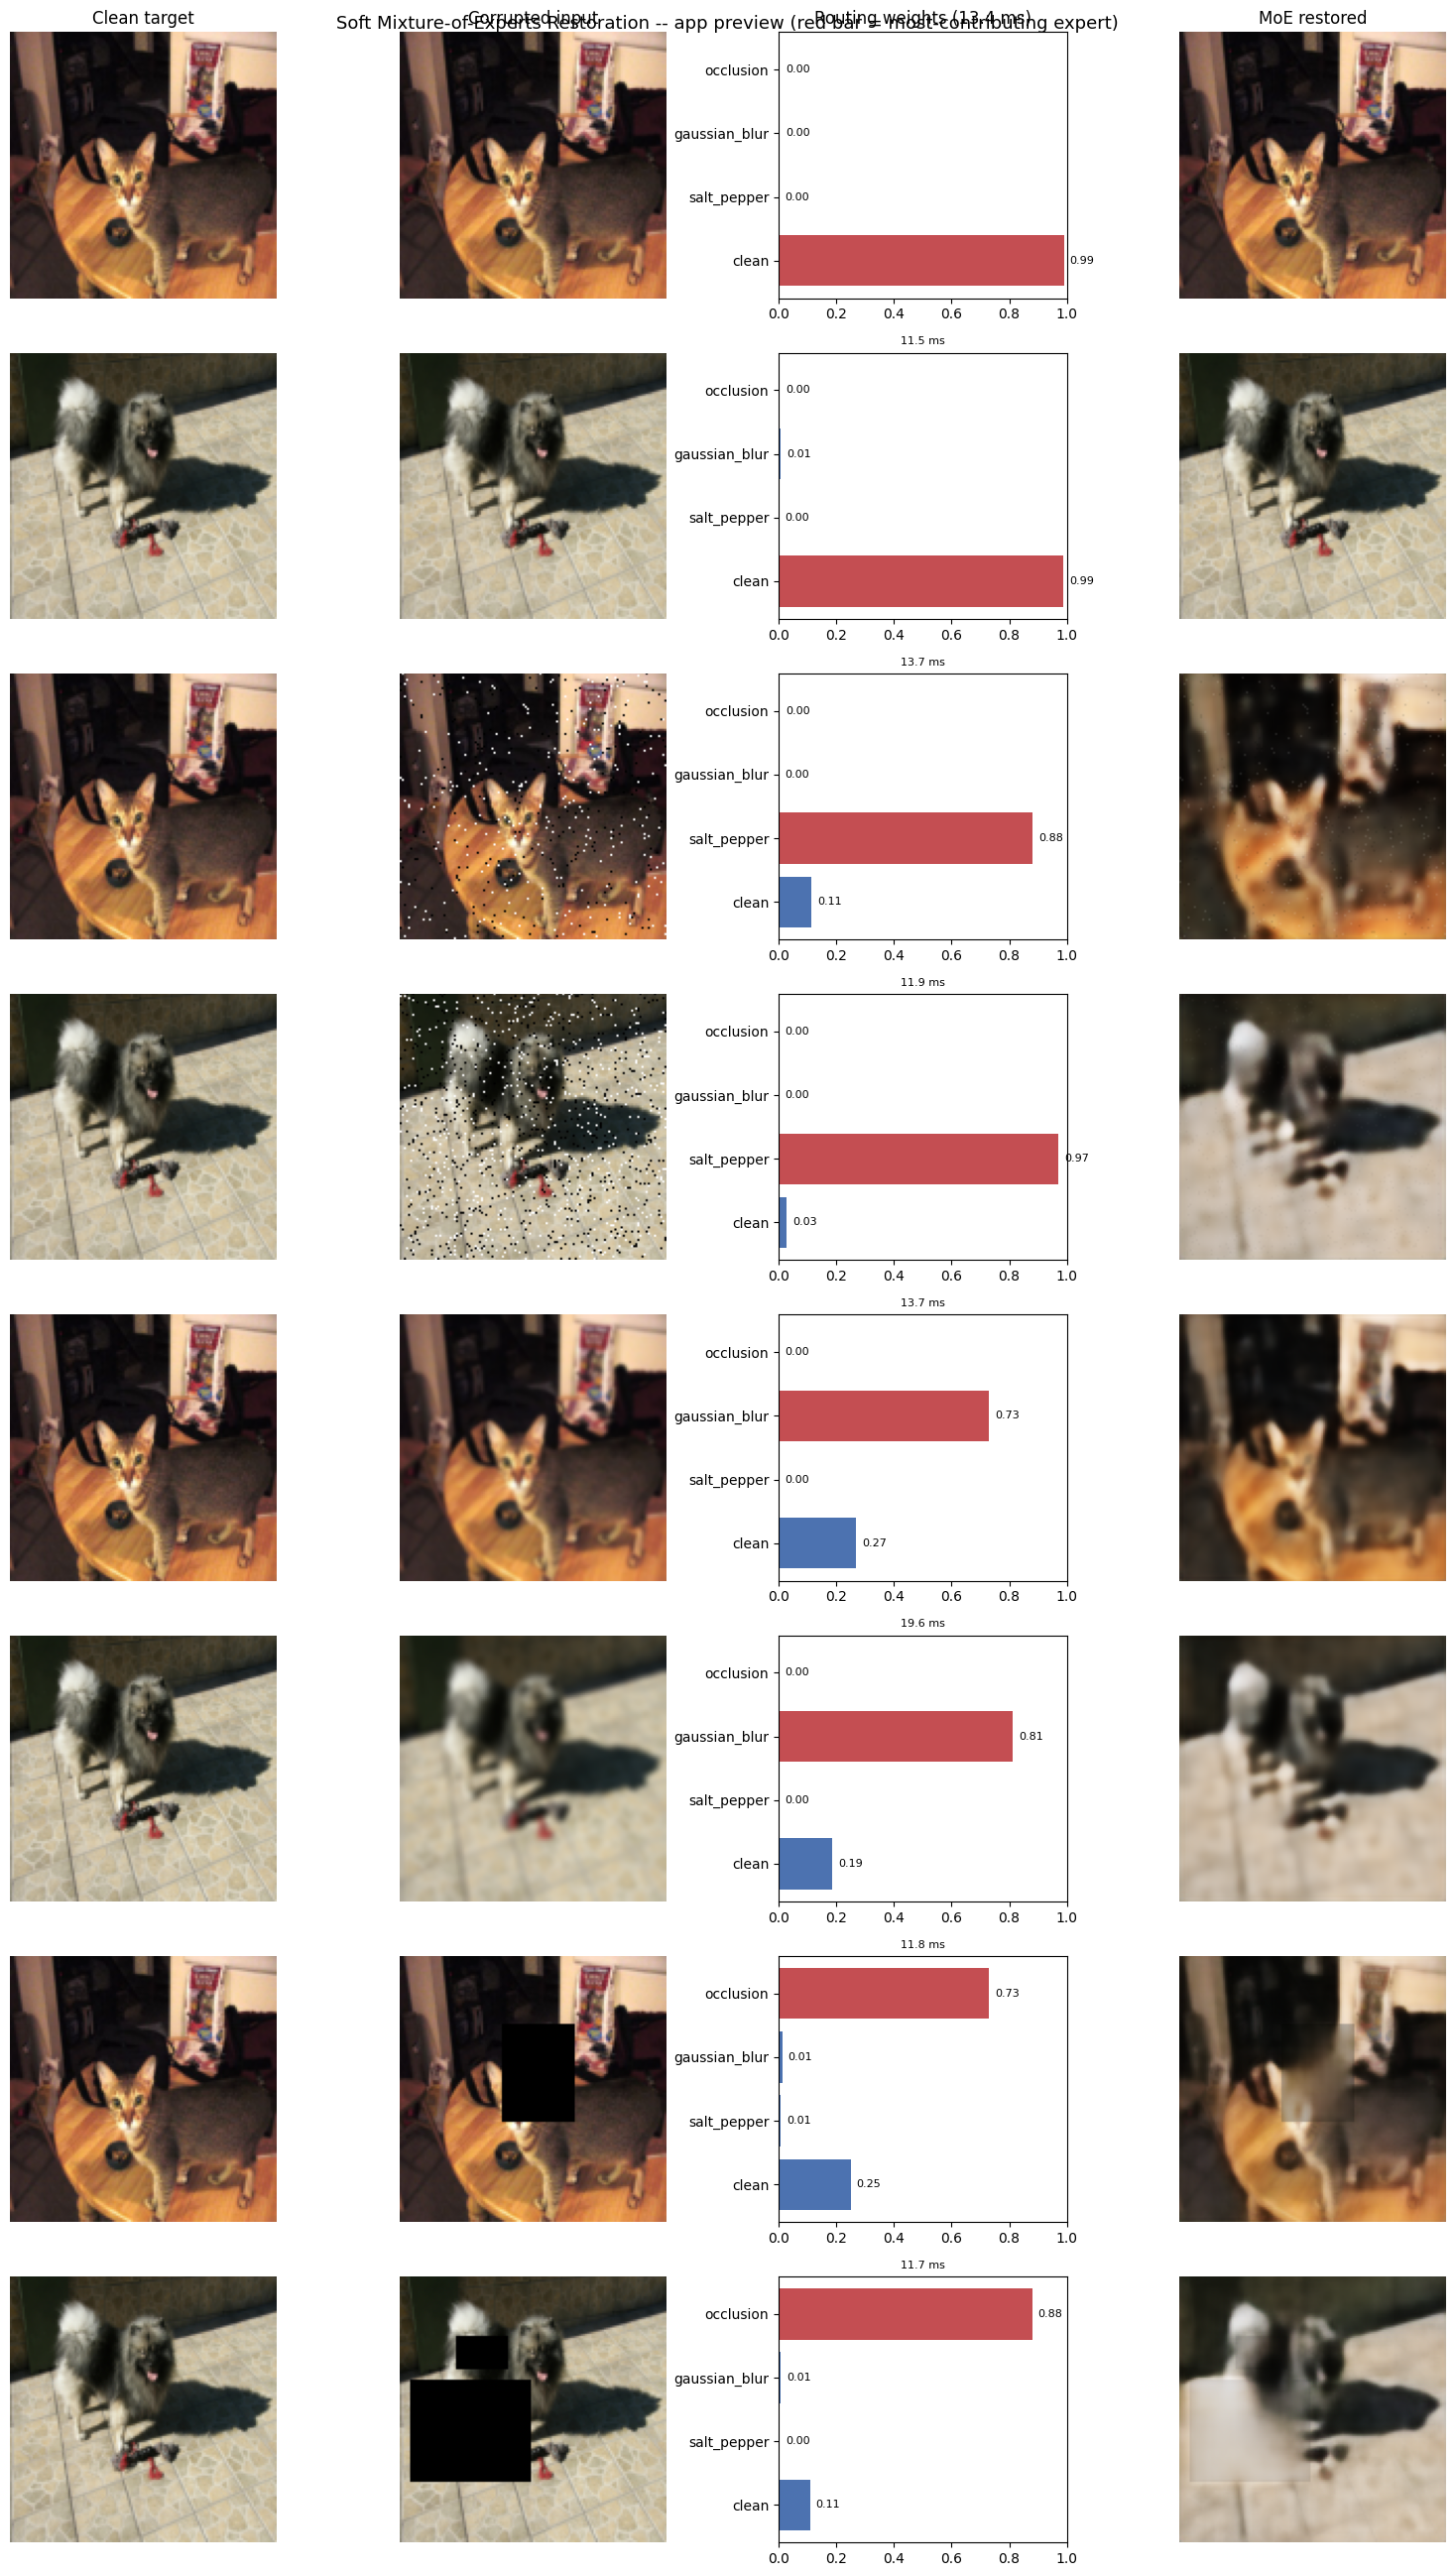

Saved to /content/drive/MyDrive/task3_artifacts/results/soft_moe_app_preview.png


In [ ]:
# ============================================================
# FINAL TEST: reload the joint-fine-tuned Soft MoE strictly from its saved
# Drive checkpoint (not whatever's in memory) and preview exactly what the
# "Soft Mixture-of-Experts Restoration" app should display: all 4 routing
# weights, the reconstructed image, inference time, and a visual
# indication of which experts contributed most strongly.
# ============================================================

_best_path = find_moe_file('moe_joint_best.pt')
assert _best_path is not None, 'moe_joint_best.pt not found -- run the joint fine-tuning cell first.'
_ckpt = torch.load(_best_path, map_location=DEVICE)
loaded_moe = build_soft_moe(temperature=_ckpt['temperature'])
loaded_moe.load_state_dict(_ckpt['model_state'])
loaded_moe.eval()
print(f'Loaded Soft MoE fresh from {_best_path} (val_loss={_ckpt["val_loss"]:.4f}, '
      f'temperature={_ckpt["temperature"]:.3f})')


@torch.no_grad()
def run_soft_moe_app(clean, corrupted, model, device=DEVICE):
    t0 = time.time()
    x_hat, w, _ = model(corrupted, return_weights=True)
    inference_ms = (time.time() - t0) * 1000
    return x_hat.clamp(0, 1), w.squeeze(0).cpu().numpy(), inference_ms


def show_soft_moe_app_preview(ds, n_per_class=2, save_name='soft_moe_app_preview.png'):
    rows = []
    for ctype in CORRUPTION_TYPES:
        matching = [i for i, e in enumerate(ds.manifest) if e['ctype'] == ctype]
        if not matching:
            continue
        rows.extend(matching[::max(1, len(matching) // n_per_class)][:n_per_class])

    n = len(rows)
    fig, axes = plt.subplots(n, 4, figsize=(15, 3.3 * n))
    if n == 1:
        axes = axes[None, :]
    col_titles = ['Clean target', 'Corrupted input', 'Routing weights', 'MoE restored']

    for row, idx in enumerate(rows):
        sample = ds[idx]
        clean = sample['clean'].unsqueeze(0).to(DEVICE)
        corrupted = sample['corrupted'].unsqueeze(0).to(DEVICE)
        true_name = CORRUPTION_TYPES[sample['label']]

        x_hat, w, inference_ms = run_soft_moe_app(clean, corrupted, loaded_moe)
        dominant_idx = int(w.argmax())

        axes[row, 0].imshow(clean[0].cpu().permute(1, 2, 0).numpy()); axes[row, 0].axis('off')
        axes[row, 0].set_ylabel(f'true={true_name}', fontsize=9)
        axes[row, 1].imshow(corrupted[0].cpu().permute(1, 2, 0).numpy()); axes[row, 1].axis('off')

        axes[row, 2].barh(CORRUPTION_TYPES, w,
                           color=['#4C72B0' if i != dominant_idx else '#C44E52' for i in range(4)])
        axes[row, 2].set_xlim(0, 1)
        for i, v in enumerate(w):
            axes[row, 2].text(v + 0.02, i, f'{v:.2f}', va='center', fontsize=8)
        axes[row, 2].set_title(f'{inference_ms:.1f} ms', fontsize=8)

        axes[row, 3].imshow(x_hat[0].cpu().permute(1, 2, 0).numpy()); axes[row, 3].axis('off')

        if row == 0:
            for col in range(4):
                axes[row, col].set_title(col_titles[col] if col != 2 else f'{col_titles[2]} ({inference_ms:.1f} ms)')

    fig.suptitle('Soft Mixture-of-Experts Restoration -- app preview '
                 '(red bar = most-contributing expert)', fontsize=13)
    plt.tight_layout()
    out_path = os.path.join(MOE_RESULTS_DIR, save_name)
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()
    print('Saved to', out_path)


show_soft_moe_app_preview(test_ds, n_per_class=2)


## Experiment tracking (MLflow)

In [ ]:
# Log the soft-MoE configuration, training history, Optuna trials, results, checkpoint, ONNX and figures to MLflow
import mlflow
MLFLOW_DIR = '/content/drive/MyDrive/mlflow_genai'
os.makedirs(MLFLOW_DIR, exist_ok=True)
mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DIR}/mlflow.db')
EXP, RUN = 'Task3-Soft-MoE', 'soft_moe_final'
if mlflow.get_experiment_by_name(EXP) is None:
    mlflow.create_experiment(EXP, artifact_location=os.path.join(MLFLOW_DIR, 'artifacts', EXP))
_exp = mlflow.set_experiment(EXP)
if len(mlflow.search_runs([_exp.experiment_id], filter_string=f"tags.mlflow.runName = '{RUN}'")):
    print(f'{RUN} already logged in MLflow.')
else:
    with mlflow.start_run(run_name=RUN):
        mlflow.log_params({**MOE_BEST_PARAMS, 'warmup_epochs': WARMUP_EPOCHS, 'warmup_lr': WARMUP_LR,
                           'max_epochs': MOE_FINAL_EPOCHS, 'init': 'Task 2 classifier + specialists'})
        for rec in history:
            mlflow.log_metrics({k: float(v) for k, v in rec.items() if k != 'epoch'}, step=int(rec['epoch']))
        for _, r in moe_summary.iterrows():
            mlflow.log_metrics({f"test_{r['ctype']}_{r['severity']}_{m}": float(r[m]) for m in ['l1', 'ssim', 'psnr']})
        for _, r in summary.iterrows():
            mlflow.log_metrics({f"avgw_{r['ctype']}_{r['severity']}_{c}": float(r[c]) for c in weight_cols})
        _op = os.path.join(MOE_RESULTS_DIR, 'moe_optuna_all_trials.json')
        if os.path.exists(_op):
            for t in json.load(open(_op)):
                with mlflow.start_run(run_name=f"optuna_trial_{t['number']}", nested=True):
                    mlflow.log_params(t['params']); mlflow.set_tag('state', t['state'])
                    if t['value'] is not None:
                        mlflow.log_metric('objective', t['value'])
        for f in glob.glob(os.path.join(MOE_RESULTS_DIR, '*.png')) + glob.glob(os.path.join(MOE_RESULTS_DIR, '*.csv')) + glob.glob(os.path.join(MOE_RESULTS_DIR, '*.json')):
            mlflow.log_artifact(f, 'results')
        mlflow.log_artifact(find_moe_file('moe_joint_best.pt'), 'checkpoint')
        mlflow.log_artifact(moe_onnx_path, 'onnx')
    print('Logged to MLflow:', mlflow.get_tracking_uri())

Logged to MLflow: sqlite:////content/drive/MyDrive/mlflow_genai/mlflow.db
